# Task 3: Policy Distillation and Speculative Decoding

Name: Muhammad Danish Zaheer Awan | REG id: 25280092

Implement exact stochastic speculative sampling, train four independent LoRA
drafts, and compare probability alignment with actual execution costs.
Colab computes and resumes. Local **ATML** Run All validates and displays saved
Colab evidence. Every main figure uses **Times New Roman, 10 pt**.


## Common setup

Upload the complete `Task_3/` folder to `MyDrive/ATML_PA4/PA_4/`. Code runs on local Colab storage; verified results and recovery checkpoints are backed up to Drive.


In [1]:
# Name : Muhammad Danish Zaheer Awan
# REG id : 25280092
from importlib.util import find_spec
from pathlib import Path
import sys
try:
    IN_COLAB = find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
RUN_MODE = 'compute' if IN_COLAB else 'replay'
DRIVE_PROJECT = 'ATML_PA4/PA_4'
print('Task_3 |', RUN_MODE, '| Colab:', IN_COLAB)


Task_3 | replay | Colab: False


### Drive and working storage

Downloaded model/data caches belong in runtime `Data/Task_3/`; this folder's `data/` package contains Python code. Preserve existing results when replacing uploaded code.


In [2]:
import shutil
if RUN_MODE == 'compute':
    from google.colab import drive
    drive.mount('/content/drive')
    drive_root = Path('/content/drive/MyDrive') / DRIVE_PROJECT
    PROJECT_ROOT = Path('/content') / DRIVE_PROJECT
    if not (drive_root / 'Task_3/main_task_3.ipynb').is_file():
        raise FileNotFoundError(f'Upload the complete Task_3 folder into {drive_root}.')
    shutil.copytree(drive_root / 'Task_3', PROJECT_ROOT / 'Task_3', dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns('results', '__pycache__', '.ipynb_checkpoints'))
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / 'Task_3/configs/base.yaml').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Open this notebook from Task_3 or the PA4 root.')
sys.path.insert(0, str(PROJECT_ROOT))


### Dependencies and exact plotting fonts

Compute checks the pinned Transformers/cache stack and genuine Times New Roman files before expensive work. Restart the runtime if an already imported package changes. Replay installs nothing and loads no model.


In [3]:
if RUN_MODE == 'compute':
    from Task_3.cloud.dependencies import install_compute_requirements
    install_compute_requirements(PROJECT_ROOT / 'Task_3')
    from Task_3.analysis.fonts import configure_fonts
    print(configure_fonts(PROJECT_ROOT / 'Task_3'))
else:
    print('Local replay: no installation, downloads, training or model loading.')


Local replay: no installation, downloads, training or model loading.


In [4]:
import pandas as pd
from IPython.display import display
from Task_3.common.config import load_configuration
from Task_3.common.pipeline import open_session
from Task_3.common.replay import display_question
configuration = load_configuration(PROJECT_ROOT / 'Task_3')
configuration['execution']['drive_project'] = DRIVE_PROJECT
pd.set_option('display.max_rows', 36)
print('Run:', configuration['execution']['run_id'])


Run: task3_seed6304_v1


### Small mathematical and implementation checks

The joint Markov test uses 100,000 length-three sequences for each gamma and each correct/incorrect residual control. Tiny random Qwen tests check cache positions, bonus tokens, padding, EOS, merging, full soft-KL targets and complete training-state recovery. These are diagnostics, not assignment-model results.


In [5]:
if RUN_MODE == 'compute':
    import unittest
    import torch
    threads = torch.get_num_threads()
    modules = ['test_sampling', 'test_lora_data', 'test_training', 'test_evaluation', 'test_recovery']
    suite = unittest.defaultTestLoader.loadTestsFromNames([f'Task_3.tests.{name}' for name in modules])
    outcome = unittest.TextTestRunner(verbosity=1).run(suite)
    torch.set_num_threads(threads)
    if not outcome.wasSuccessful():
        raise RuntimeError('Small correctness checks failed; full experiments have not started.')
else:
    print('Replay verifies the saved cloud experiment instead of executing compute diagnostics.')


Replay verifies the saved cloud experiment instead of executing compute diagnostics.


### Restore compatible progress or validate downloaded evidence

Recovery includes adapters, optimizer/scaler, quota counters, prompt-schedule state, pending response, histories and RNGs every five successful updates. Scientific code, data, GPU and package identities must match. Local replay never falls back to computation.


In [6]:
session = open_session(configuration, PROJECT_ROOT, RUN_MODE)
print('Results:', session.paths['results'])


Validating 13029 Task 3 evidence files...


Verified four 40,000-token runs, training annotations and adapter merges.


Verified seven frozen prefix banks and all five drafts on identical prefix IDs.


Verified baseline: 480 adjacent-control pairs.


Verified primary: 2400 adjacent-control pairs.


Verified fixed64: 480 adjacent-control pairs.


Replay only | original computation: Google Colab | task3_seed6304_v1
Results: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_4\Task_3\results\task3_seed6304_v1


## Data preparation

Use the exact 500 GSM8K training IDs and 300 supplied short-form training prompts. Freeze the 120 held-out prompts: 60 math, 30 familiar extraction, 30 shifted extraction. Download only the pinned GSM8K source rows; verify all 920 teacher/student chat encodings. No raw Data upload is needed.


In [7]:
display(session.prepare_data())


{'supplied_hashes': {'data/public_manifests/gsm8k_train_ids.jsonl': '81d9f027fe14382d34dc2fc6a2f3cd19ba97d2a59dfec0a9f4fd1c56b4e8416d',
  'data/public_manifests/gsm8k_test_ids.jsonl': 'b0ad559360962ffe9445161d9e01d3f1f2ab75aa54cba1ad2d91346366b6dd55',
  'data/short_form/short_train.jsonl': '50eb7a8240bb1e8bd17eef6e4758d4309a0369d330608ef419df14cd8eda67e5',
  'data/short_form/short_test.jsonl': '2563b25d65f43b92a179a22dd2fd4621dfe209758927a6ee29022798ec4e6b5d'},
 'source_revisions': {'gsm8k': '740312add88f781978c0658806c59bc2815b9866',
  'target': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306',
  'draft': '7ae557604adf67be50417f59c2c2f167def9a775'},
 'train_ids': ['GSM8K-train-0000',
  'GSM8K-train-0001',
  'GSM8K-train-0002',
  'GSM8K-train-0003',
  'GSM8K-train-0004',
  'GSM8K-train-0005',
  'GSM8K-train-0006',
  'GSM8K-train-0007',
  'GSM8K-train-0008',
  'GSM8K-train-0009',
  'GSM8K-train-0010',
  'GSM8K-train-0011',
  'GSM8K-train-0012',
  'GSM8K-train-0013',
  'GSM8K-train-0014',
  'G

## Step 1: Exact speculative sampling and cache correctness

Use stochastic min(1,p/q) acceptance, the normalized positive residual on rejection and a target bonus token after full acceptance. A single target verification handles proposals plus the previous pending token. Both caches retain the committed context except that one pending token. Preserve actual draft/target work and all four synchronized round-time components. Validate joint laws and real-model split-prefill/crop equivalence before timing.


In [8]:
display(session.validate_sampler())


[{'gamma': 2,
  'negative_control': False,
  'trials': 100000,
  'chi_square': 26.899656526318577,
  'p_value': 0.4146097377385883,
  'passed': True,
  'minimum_expected_count': 200.00000000000006},
 {'gamma': 2,
  'negative_control': True,
  'trials': 100000,
  'chi_square': 41047.31736180114,
  'p_value': 0.0,
  'passed': True,
  'minimum_expected_count': 200.00000000000006},
 {'gamma': 4,
  'negative_control': False,
  'trials': 100000,
  'chi_square': 31.58972129257441,
  'p_value': 0.20703639221911824,
  'passed': True,
  'minimum_expected_count': 200.00000000000006},
 {'gamma': 4,
  'negative_control': True,
  'trials': 100000,
  'chi_square': 49706.32818312333,
  'p_value': 0.0,
  'passed': True,
  'minimum_expected_count': 200.00000000000006}]

## Step 2: Pretrained draft baseline

Benchmark the original 0.5B draft at gamma=2/4, two paired repetitions on all 120 prompts, EOS-aware cap 64. Each speculative request has an adjacent target-only control. Save warm setup, prefill, steady decode, accepted/examined and accepted/proposed counters, target passes and actual draft work. Isolate single-step and verification costs at context lengths 64/256/512.


In [9]:
display(session.baseline())


{'status': 'saved pretrained baseline', 'paired_records': 480}

## Step 3: Off-policy full-vocabulary distillation

For each seed 6304/6305, first freeze an 800-prompt teacher rollout pool. Independently initialize FP32 rank-8 LoRA adapters on the frozen FP16 original student. Score exactly 30,000 math and 10,000 short-form response prefixes, accumulating one update per 256 tokens with a final 64-token update. Teacher soft probabilities, never sampled hard tokens, define forward KL.


In [10]:
display(pd.DataFrame(session.train_method('off_policy')))


,id,method,seed,status,teacher_scored_tokens,successful_optimizer_updates,overflow_attempts,initialization_sha256,adapter_sha256,trainable_parameters,...,teacher_pool_generation_seconds,student_rollout_seconds,teacher_scoring_seconds,student_backward_and_optimizer_seconds,current_session_wall_seconds,final_selection,adapter_precision,backbone_precision,peak_allocated_bytes,peak_reserved_bytes
0,off_policy_seed6304,off_policy,6304,complete,"{'math': 30000, 'short': 10000}",157,0,30bd3f445cb203b57d4ca923be6670aba7b1fc5a60fea4...,00a358fdc888ded38ccc530c698b3772ddf0e84ff45de4...,1081344,...,3378.360252,0.0,53.964058,194.477290,269.691069,last update at fixed token quota; no test-base...,float32,float16,5282826752,5523898368
1,off_policy_seed6305,off_policy,6305,complete,"{'math': 30000, 'short': 10000}",157,1,a911e84d110d6a530a27b18cdf81216dfcfd29ca60c030...,ec1d56f1ca40a0cb6f712e6138630bca7ea87d526ef20b...,1081344,...,3407.702978,0.0,53.889299,195.318552,274.503960,last update at fixed token quota; no test-base...,float32,float16,5285545984,5523898368


## Step 4: On-policy full-vocabulary distillation

Independently restart from the original backbone and matching seeded LoRA initialization. Generate fresh current-student responses using the same seeded category round-robin schedule and response caps. Teacher-score these prefixes to the identical 30,000/10,000 quotas. Freeze rollout generation from autograd; count student generation separately. Reuse scored soft targets during scaler retries instead of adding teacher-scored tokens.


In [11]:
display(pd.DataFrame(session.train_method('on_policy')))


,id,method,seed,status,teacher_scored_tokens,successful_optimizer_updates,overflow_attempts,initialization_sha256,adapter_sha256,trainable_parameters,...,teacher_pool_generation_seconds,student_rollout_seconds,teacher_scoring_seconds,student_backward_and_optimizer_seconds,current_session_wall_seconds,final_selection,adapter_precision,backbone_precision,peak_allocated_bytes,peak_reserved_bytes
0,on_policy_seed6304,on_policy,6304,complete,"{'math': 30000, 'short': 10000}",157,1,30bd3f445cb203b57d4ca923be6670aba7b1fc5a60fea4...,2ff9dda20797f6248d04cac9005e91666d43c866e547ed...,1081344,...,0.0,1838.321972,51.52129,186.035325,2099.073459,last update at fixed token quota; no test-base...,float32,float16,4343878656,5549064192
1,on_policy_seed6305,on_policy,6305,complete,"{'math': 30000, 'short': 10000}",157,1,a911e84d110d6a530a27b18cdf81216dfcfd29ca60c030...,1531506614888e94503fd4fd23b5ce1fcefe728665e60e...,1081344,...,0.0,1828.672925,51.70253,186.686952,173.774504,last update at fixed token quota; no test-base...,float32,float16,4343878656,4626317312


## Step 5: Common and own-policy prefix banks

The supplied data-only checkout has no materialized prefix banks. Generate and freeze teacher, original-student and exact-original-speculative banks, plus all four trained students' own banks. Score all five drafts on every bank with identical saved prefix IDs, up to 32 positions in 1-64 and a separate long diagnostic at 65-192. Teacher and exact-speculative banks are independent realizations of the same target law. Own-bank cross-evaluation retains named producing checkpoints.


In [12]:
display(session.alignment())


{'status': 'saved paired-prefix evidence', 'banks': 7, 'drafts': 5}

## Step 6: Merged drafts and measured speculative execution

Merge every adapter into a fresh FP16 backbone and verify logits against the corresponding unmerged model. Primary benchmarks use ordinary merged projections, all 120 prompts, both gamma values and two repetitions. Reverse model order across repetitions, alternate gamma order and counterbalance adjacent target/speculative order. Measure one fixed unmerged-adapter control separately.


In [13]:
display(session.merged_execution())


{'status': 'saved merged-draft benchmarks', 'paired_records': 2400}

## Step 7: Workload, response length, quality and deployment cost

Run an additional fixed-64-token diagnostic on the first 24 supplied math prompts, ignoring EOS for timing only. Evaluate standalone teacher/draft answer quality separately at 512 math / 32 extraction tokens, retaining extraction failures and truncations. Build prompt-paired 95% intervals and compare measured costs with the analytical model; a nonpositive saving has no finite deployment break-even.


In [14]:
display(session.workload_evaluation())


{'status': 'saved workload/quality evidence',
 'fixed64_pairs': 480,
 'standalone_quality_records': 1440}

## Build required evidence

All required stages must finish before the final evidence registry exists. Generate machine-readable tables and nine main PNGs, all Times New Roman 10 pt. Poor outcomes remain; there is no tuning on held-out prefixes or final accuracy.


In [15]:
display(session.build_evidence())


{'status': 'saved evidence', 'figures': 9, 'font': 'Times New Roman, 10 pt'}

# Required evidence

Use the saved numerical evidence to write your own report language, interpretation and analysis.


## RQ-1: Prefix distribution, soft distillation and target-law consistency


In [16]:
display_question(session, 'rq1', 'tables')


tables/sampler_conditions.csv


,gamma,negative_control,trials,chi_square,p_value,passed,minimum_expected_count
0,2,False,100000,26.899657,0.414610,True,200.0
1,2,True,100000,41047.317362,0.000000,True,200.0
2,4,False,100000,31.589721,0.207036,True,200.0
3,4,True,100000,49706.328183,0.000000,True,200.0


tables/distillation_summary.csv


,id,method,seed,trainable_parameters,total_parameters,successful_optimizer_updates,overflow_attempts,adapter_sha256,math_scored_tokens,short_scored_tokens,reported_training_peak_allocated_bytes,reported_training_peak_reserved_bytes,training_memory_scope,merge_maximum_relative_l2
0,off_policy_seed6304,off_policy,6304,1081344,495114112,157,0,00a358fdc888ded38ccc530c698b3772ddf0e84ff45de4...,30000,10000,5282826752,5523898368,entire uninterrupted training session,0.003302
1,on_policy_seed6304,on_policy,6304,1081344,495114112,157,1,2ff9dda20797f6248d04cac9005e91666d43c866e547ed...,30000,10000,4343878656,5549064192,observed peak since last rollout reset; not ce...,0.003638
2,off_policy_seed6305,off_policy,6305,1081344,495114112,157,1,ec1d56f1ca40a0cb6f712e6138630bca7ea87d526ef20b...,30000,10000,5285545984,5523898368,entire uninterrupted training session,0.002836
3,on_policy_seed6305,on_policy,6305,1081344,495114112,157,1,1531506614888e94503fd4fd23b5ce1fcefe728665e60e...,30000,10000,4343878656,4626317312,observed peak since last rollout reset; not ce...,0.003853


tables/common_prefix_summary.csv
Showing 24/280 saved rows; full data are in the CSV.


,draft,bank,workload,position_bin,forward_kl,reverse_kl,tv,expected_acceptance,greedy_agreement,prefix_positions
0,off_policy_seed6304,exact_spec_original_gamma4,math,1_16,0.109998,0.166889,0.104390,0.895610,0.912500,480
1,off_policy_seed6304,exact_spec_original_gamma4,math,17_32,0.161015,0.240945,0.140199,0.859801,0.870833,480
2,off_policy_seed6304,exact_spec_original_gamma4,math,33_64,0.132144,0.202743,0.108472,0.891528,0.902748,946
3,off_policy_seed6304,exact_spec_original_gamma4,math,65_192,0.102520,0.145881,0.081397,0.918603,0.934322,944
4,off_policy_seed6304,exact_spec_original_gamma4,familiar,1_16,0.046420,0.064668,0.063947,0.936053,0.971264,174
5,off_policy_seed6304,exact_spec_original_gamma4,familiar,17_32,0.190070,0.265075,0.166572,0.833428,0.833333,48
6,off_policy_seed6304,exact_spec_original_gamma4,shifted,1_16,0.390640,0.435321,0.159207,0.840793,0.844595,148
7,off_policy_seed6304,exact_spec_original_gamma4,shifted,17_32,0.376631,0.609734,0.253940,0.746060,0.675676,37
8,off_policy_seed6305,exact_spec_original_gamma4,math,1_16,0.105116,0.153981,0.101136,0.898864,0.906250,480
9,off_policy_seed6305,exact_spec_original_gamma4,math,17_32,0.163119,0.235280,0.139008,0.860992,0.854167,480


tables/target_speculative_consistency.csv


,workload,position_bin,metric,estimate,ci_low,ci_high,paired_prompts,resamples,repetition_unit,comparison
0,familiar,17_32,forward_kl,-0.065837,-0.289263,0.157590,4,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
1,familiar,17_32,tv,0.019363,-0.089899,0.128626,4,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
2,familiar,17_32,expected_acceptance,-0.019363,-0.128626,0.089899,4,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
3,familiar,1_16,forward_kl,-0.106535,-0.229383,-0.006895,30,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
4,familiar,1_16,tv,-0.033381,-0.068809,0.001344,30,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
5,familiar,1_16,expected_acceptance,0.033381,-0.001344,0.068809,30,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
6,math,17_32,forward_kl,-0.008816,-0.061374,0.039176,60,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
7,math,17_32,tv,0.013035,-0.009490,0.034716,60,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
8,math,17_32,expected_acceptance,-0.013035,-0.034716,0.009490,60,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...
9,math,1_16,forward_kl,-0.019171,-0.070597,0.025243,60,2000,two repetitions averaged within prompt before ...,speculative minus teacher bank; independent ta...


figures/sampler_correctness.png


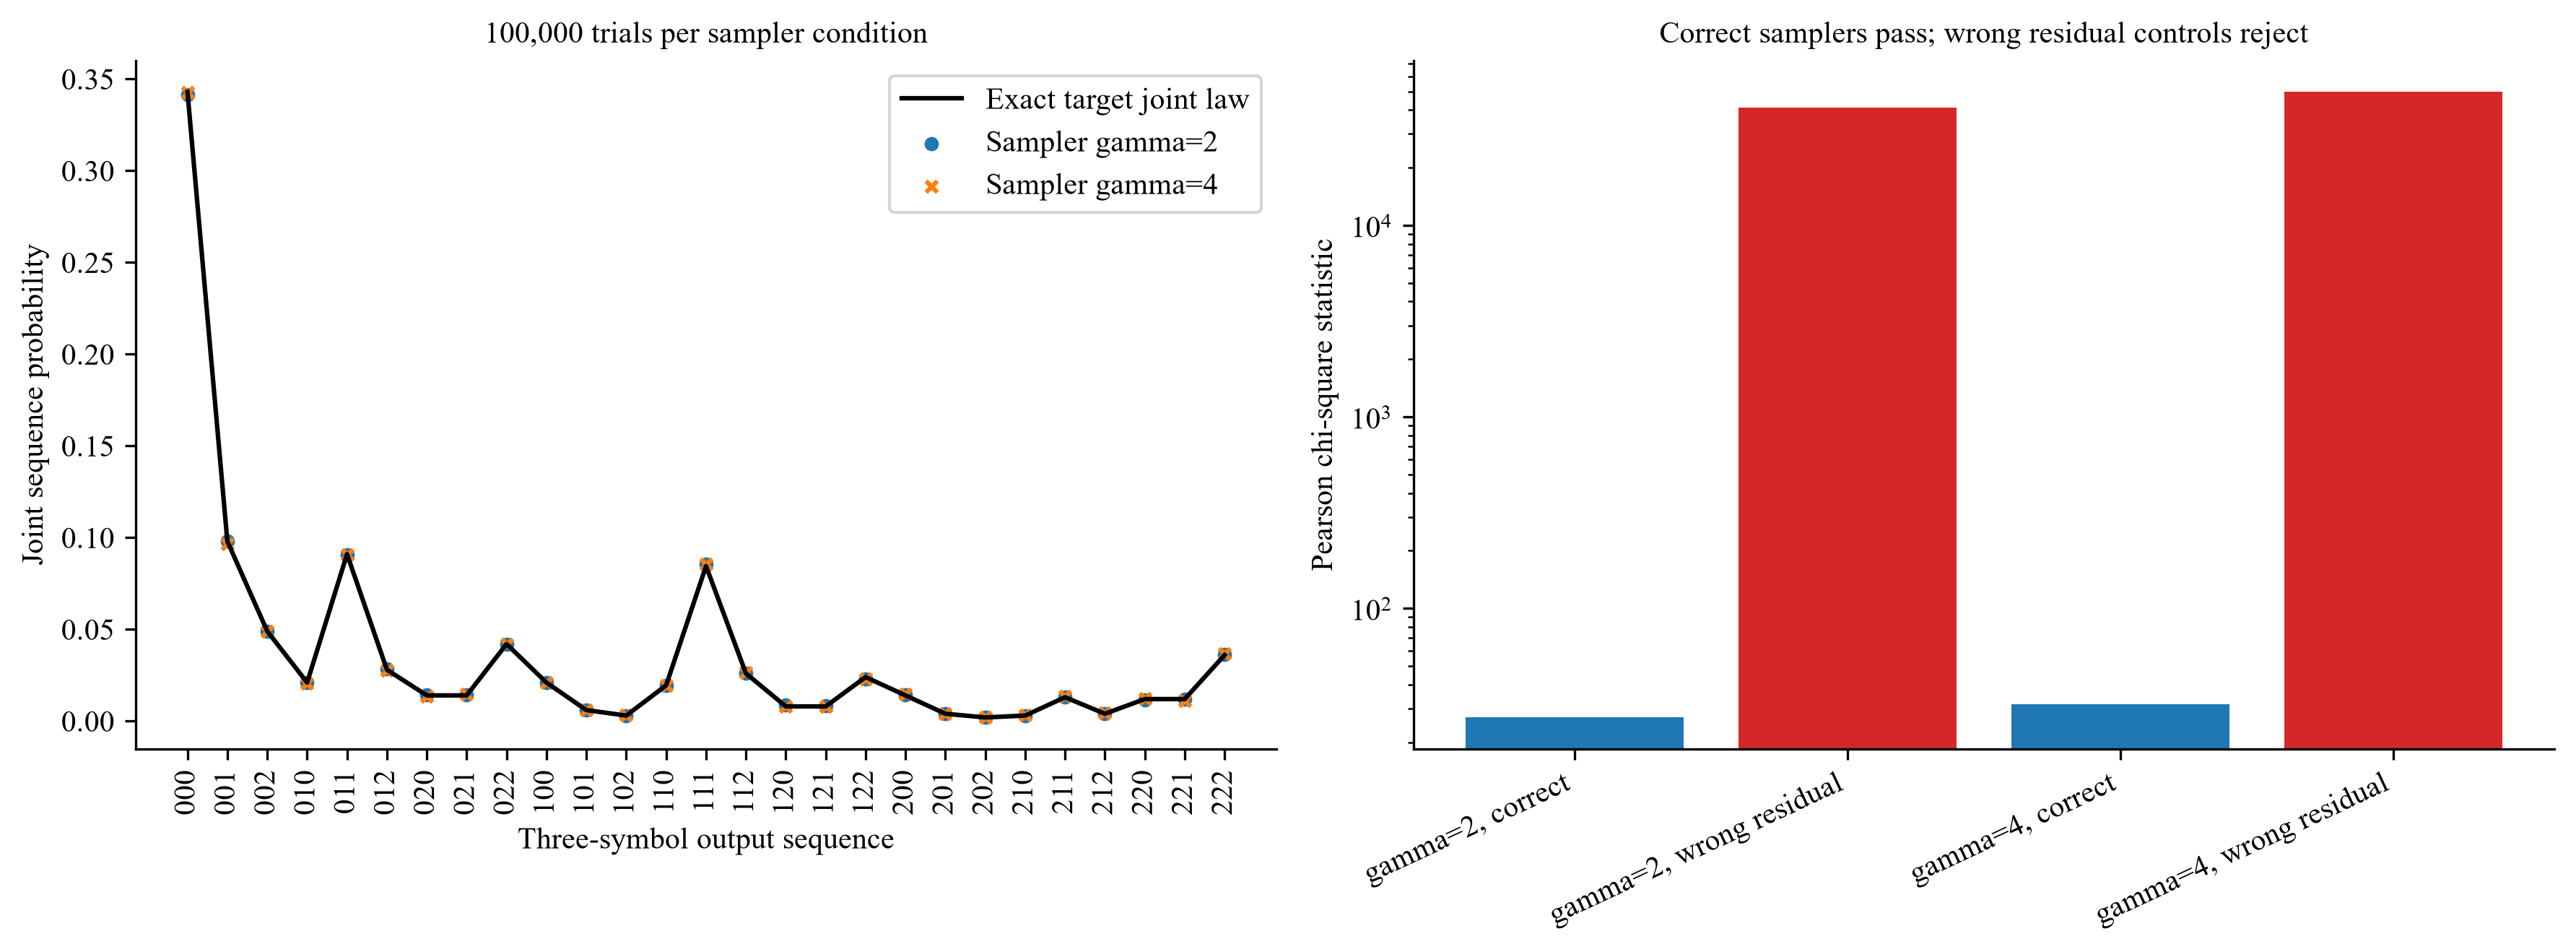

figures/distillation_curves.png


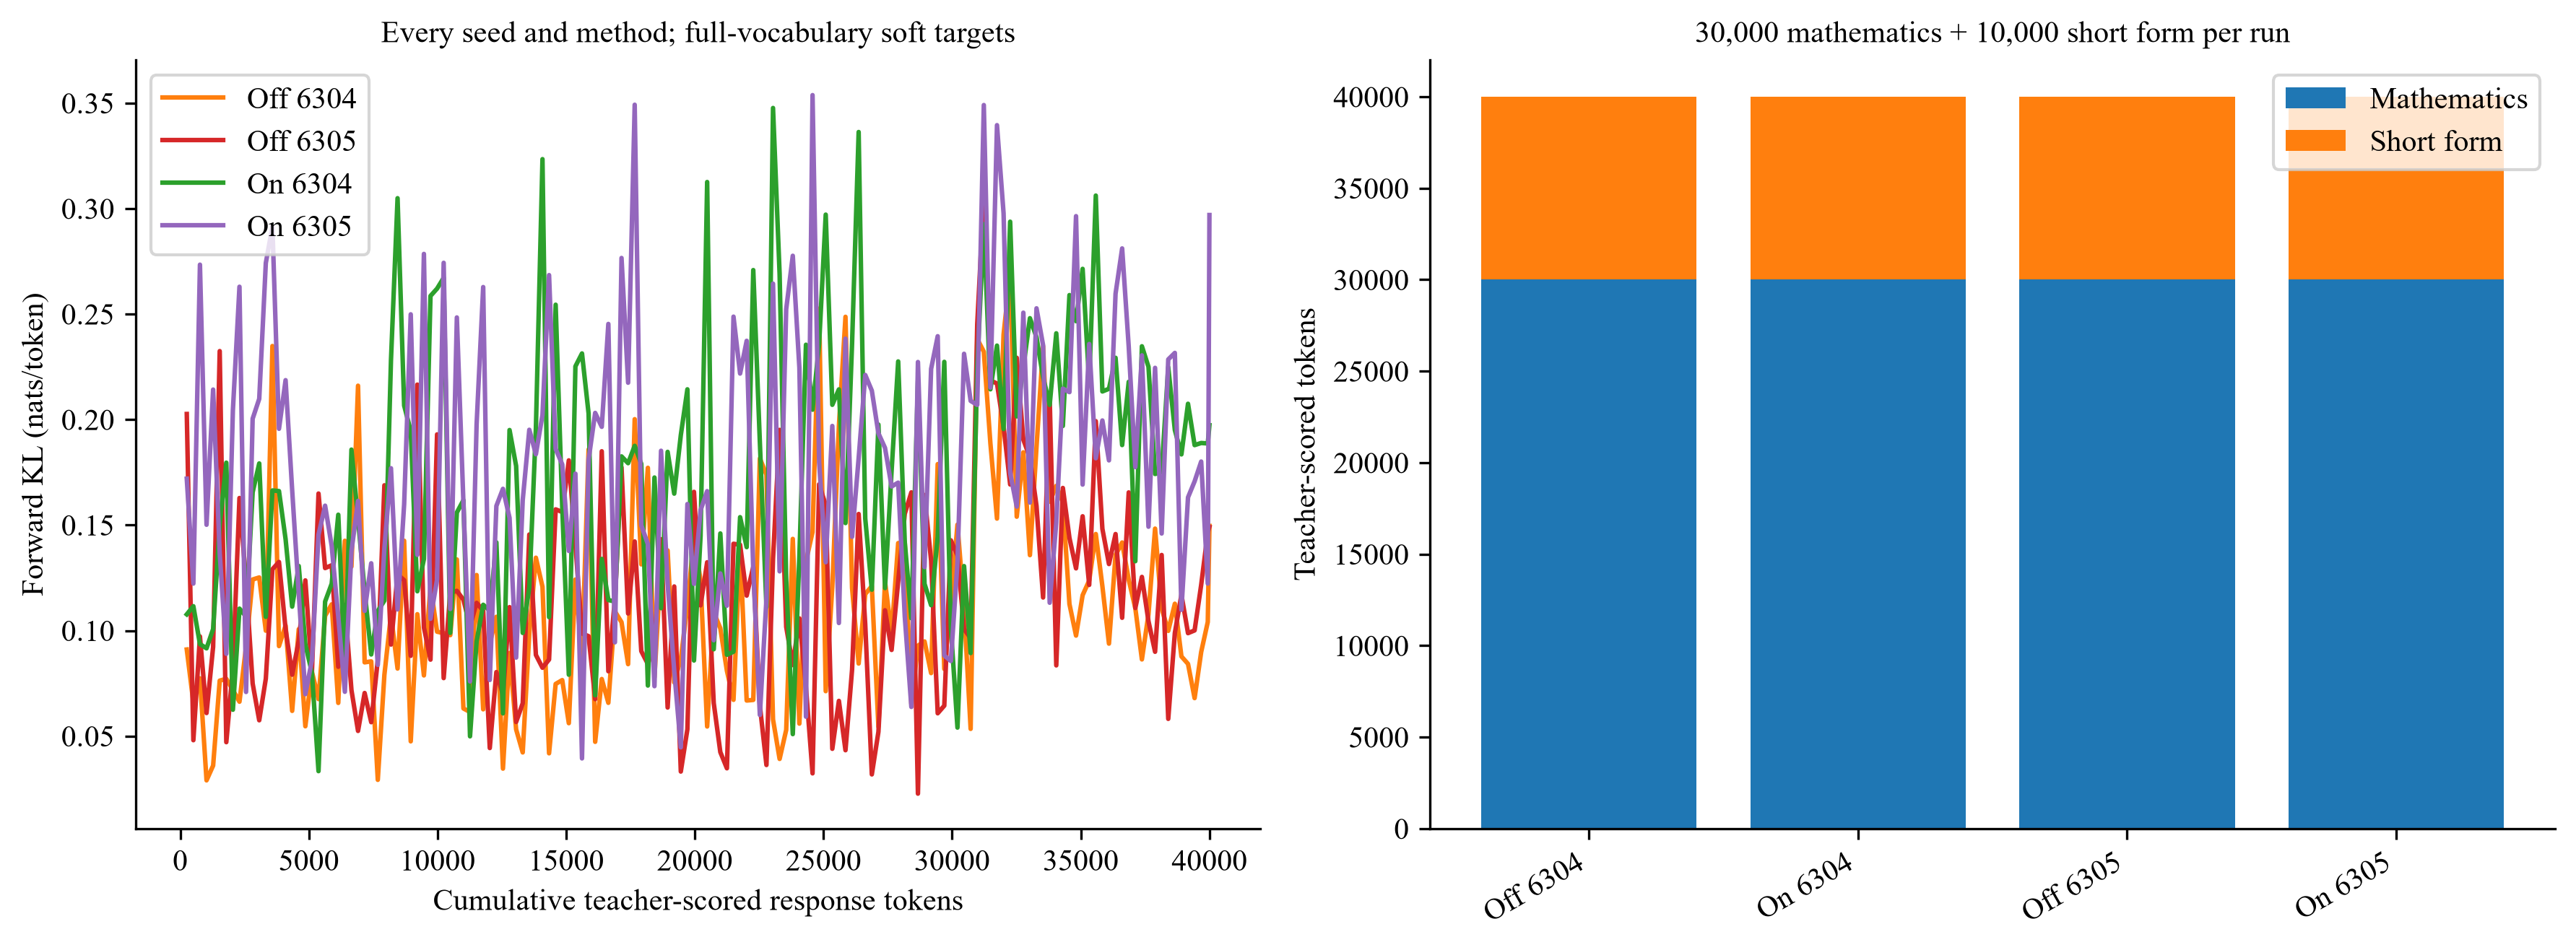

figures/common_prefix_alignment.png


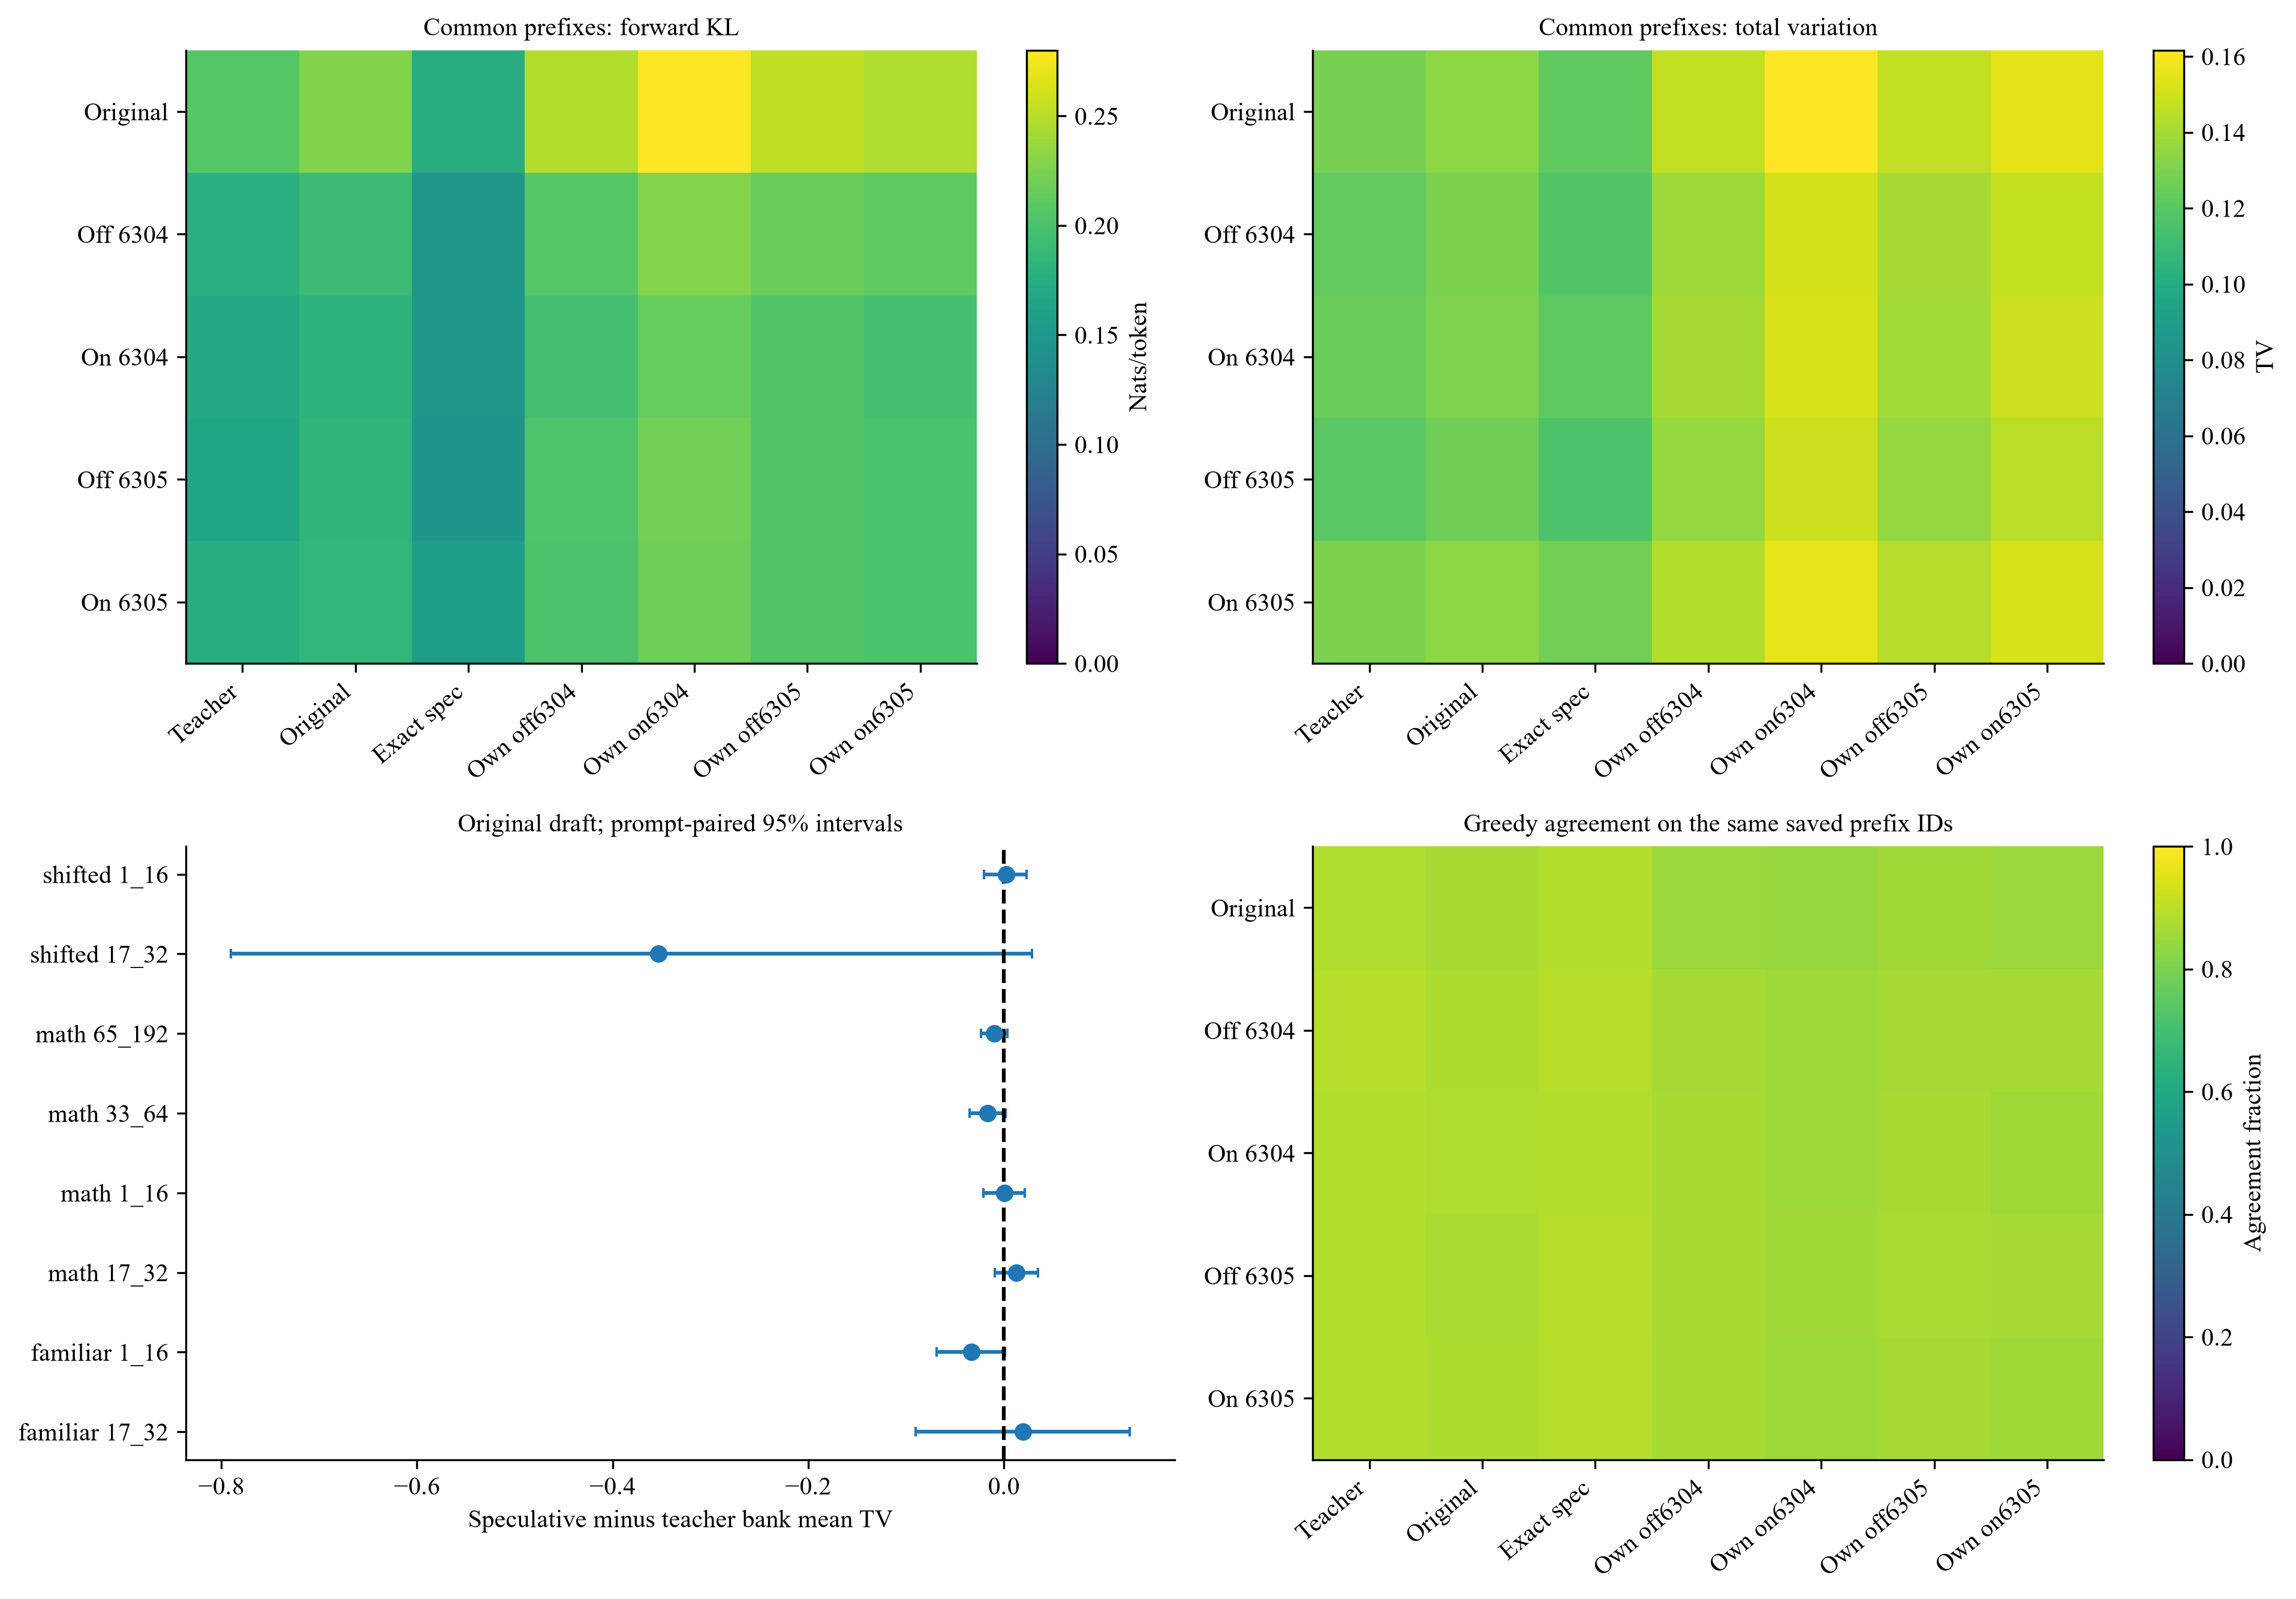

In [17]:
display_question(session, 'rq1', 'figures')


In [18]:
display_question(session, 'rq1', 'metrics')


metrics/sampler_markov.json


{'status': 'passed',
 'seed': 6304,
 'sequence_length': 3,
 'target_transition': [[0.7, 0.2, 0.1], [0.15, 0.65, 0.2], [0.2, 0.2, 0.6]],
 'draft_transition': [[0.15, 0.2, 0.65], [0.5, 0.1, 0.4], [0.6, 0.3, 0.1]],
 'initial_state': 0,
 'conditions': [{'gamma': 2,
   'negative_control': False,
   'trials': 100000,
   'chi_square': 26.899656526318577,
   'p_value': 0.4146097377385883,
   'passed': True,
   'minimum_expected_count': 200.00000000000006},
  {'gamma': 2,
   'negative_control': True,
   'trials': 100000,
   'chi_square': 41047.31736180114,
   'p_value': 0.0,
   'passed': True,
   'minimum_expected_count': 200.00000000000006},
  {'gamma': 4,
   'negative_control': False,
   'trials': 100000,
   'chi_square': 31.58972129257441,
   'p_value': 0.20703639221911824,
   'passed': True,
   'minimum_expected_count': 200.00000000000006},
  {'gamma': 4,
   'negative_control': True,
   'trials': 100000,
   'chi_square': 49706.32818312333,
   'p_value': 0.0,
   'passed': True,
   'minimum_e

metrics/cache_checks.json


{'status': 'passed',
 'conditions': [{'model': 'teacher',
   'prompt_id': 'GSM8K-train-0000',
   'split_relative_l2': 0.004077010788023472,
   'rollback_relative_l2': 0.004077010788023472,
   'tokens': 102,
   'status': 'passed'},
  {'model': 'teacher',
   'prompt_id': 'GSM8K-train-0001',
   'split_relative_l2': 0.0022013310808688402,
   'rollback_relative_l2': 0.0022013310808688402,
   'tokens': 93,
   'status': 'passed'},
  {'model': 'teacher',
   'prompt_id': 'SHORT-train-0000',
   'split_relative_l2': 0.0016258559189736843,
   'rollback_relative_l2': 0.0016258559189736843,
   'tokens': 50,
   'status': 'passed'},
  {'model': 'teacher',
   'prompt_id': 'SHORT-train-0001',
   'split_relative_l2': 0.00430808262899518,
   'rollback_relative_l2': 0.00430808262899518,
   'tokens': 53,
   'status': 'passed'},
  {'model': 'original',
   'prompt_id': 'GSM8K-train-0000',
   'split_relative_l2': 0.00520224729552865,
   'rollback_relative_l2': 0.00520224729552865,
   'tokens': 102,
   'status'

## RQ-2: Workload, output length, prefix position and standalone quality


In [19]:
display_question(session, 'rq2', 'tables')


tables/standalone_quality_summary.csv


,draft,workload,correct,extractable,format_compliant,truncated,output_tokens,responses
0,off_policy_seed6304,familiar,0.933333,0.983333,0.316667,0.350000,17.900000,60
1,off_policy_seed6304,math,0.258333,1.000000,1.000000,0.175000,304.866667,120
2,off_policy_seed6304,shifted,0.933333,0.983333,0.816667,0.000000,3.750000,60
3,off_policy_seed6305,familiar,0.933333,0.983333,0.316667,0.366667,18.250000,60
4,off_policy_seed6305,math,0.333333,1.000000,1.000000,0.125000,298.716667,120
5,off_policy_seed6305,shifted,0.966667,1.000000,0.750000,0.066667,5.750000,60
6,on_policy_seed6304,familiar,0.933333,0.966667,0.350000,0.300000,16.133333,60
7,on_policy_seed6304,math,0.225000,0.991667,0.991667,0.233333,322.725000,120
8,on_policy_seed6304,shifted,0.916667,0.983333,0.816667,0.033333,4.800000,60
9,on_policy_seed6305,familiar,0.916667,0.983333,0.383333,0.300000,15.783333,60


tables/output_length_diagnostics.csv
Showing 24/73 saved rows; full data are in the CSV.


,draft,gamma,workload,actual_output_length_bin,accepted_examined_fraction,end_to_end_tps_ratio,target_passes_per_output_token
0,off_policy_seed6304,2,familiar,17_32,0.926136,0.706935,0.412468
1,off_policy_seed6304,2,familiar,1_16,0.950772,0.511955,0.817636
2,off_policy_seed6304,2,familiar,33_64,0.850562,0.676260,0.416443
3,off_policy_seed6304,2,math,33_64,0.879210,0.694470,0.398682
4,off_policy_seed6304,2,shifted,17_32,0.742231,0.590731,0.502890
5,off_policy_seed6304,2,shifted,1_16,0.902486,0.497030,0.789550
6,off_policy_seed6304,2,shifted,33_64,0.806704,0.643413,0.429688
7,off_policy_seed6304,4,familiar,17_32,0.951590,0.770770,0.289907
8,off_policy_seed6304,4,familiar,1_16,0.948662,0.495325,0.816095
9,off_policy_seed6304,4,familiar,33_64,0.842055,0.656577,0.310558


figures/workload_position.png


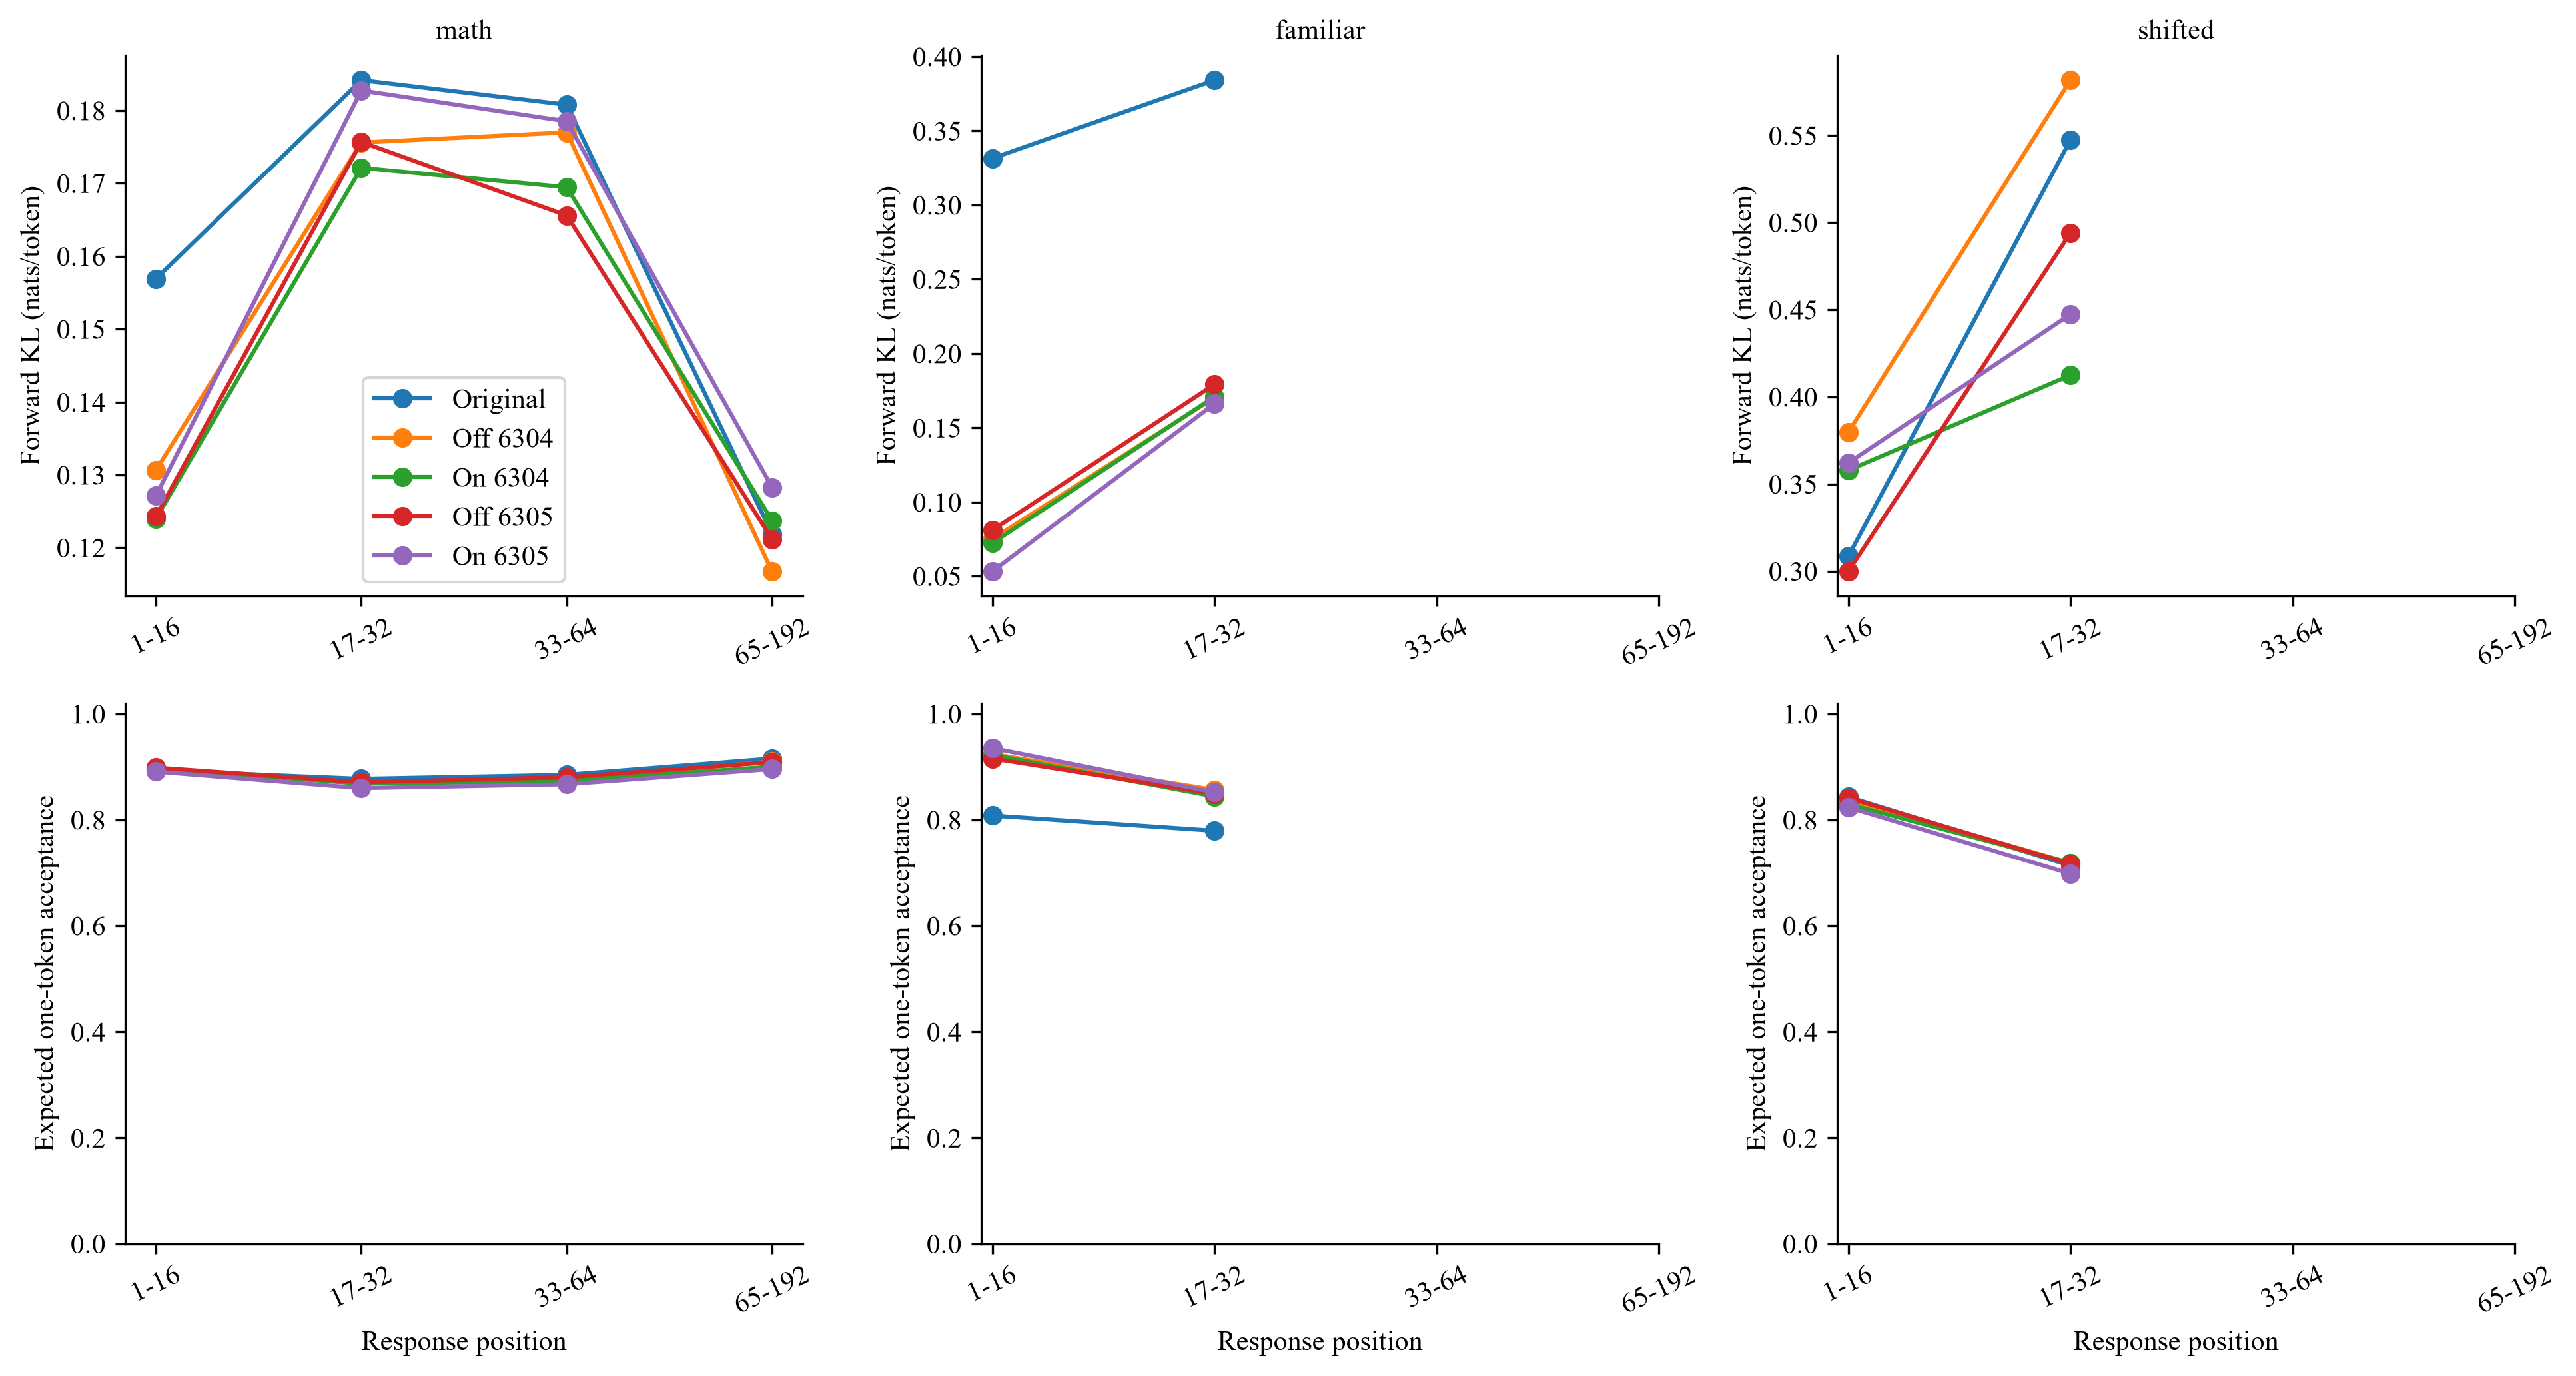

figures/quality_and_lengths.png


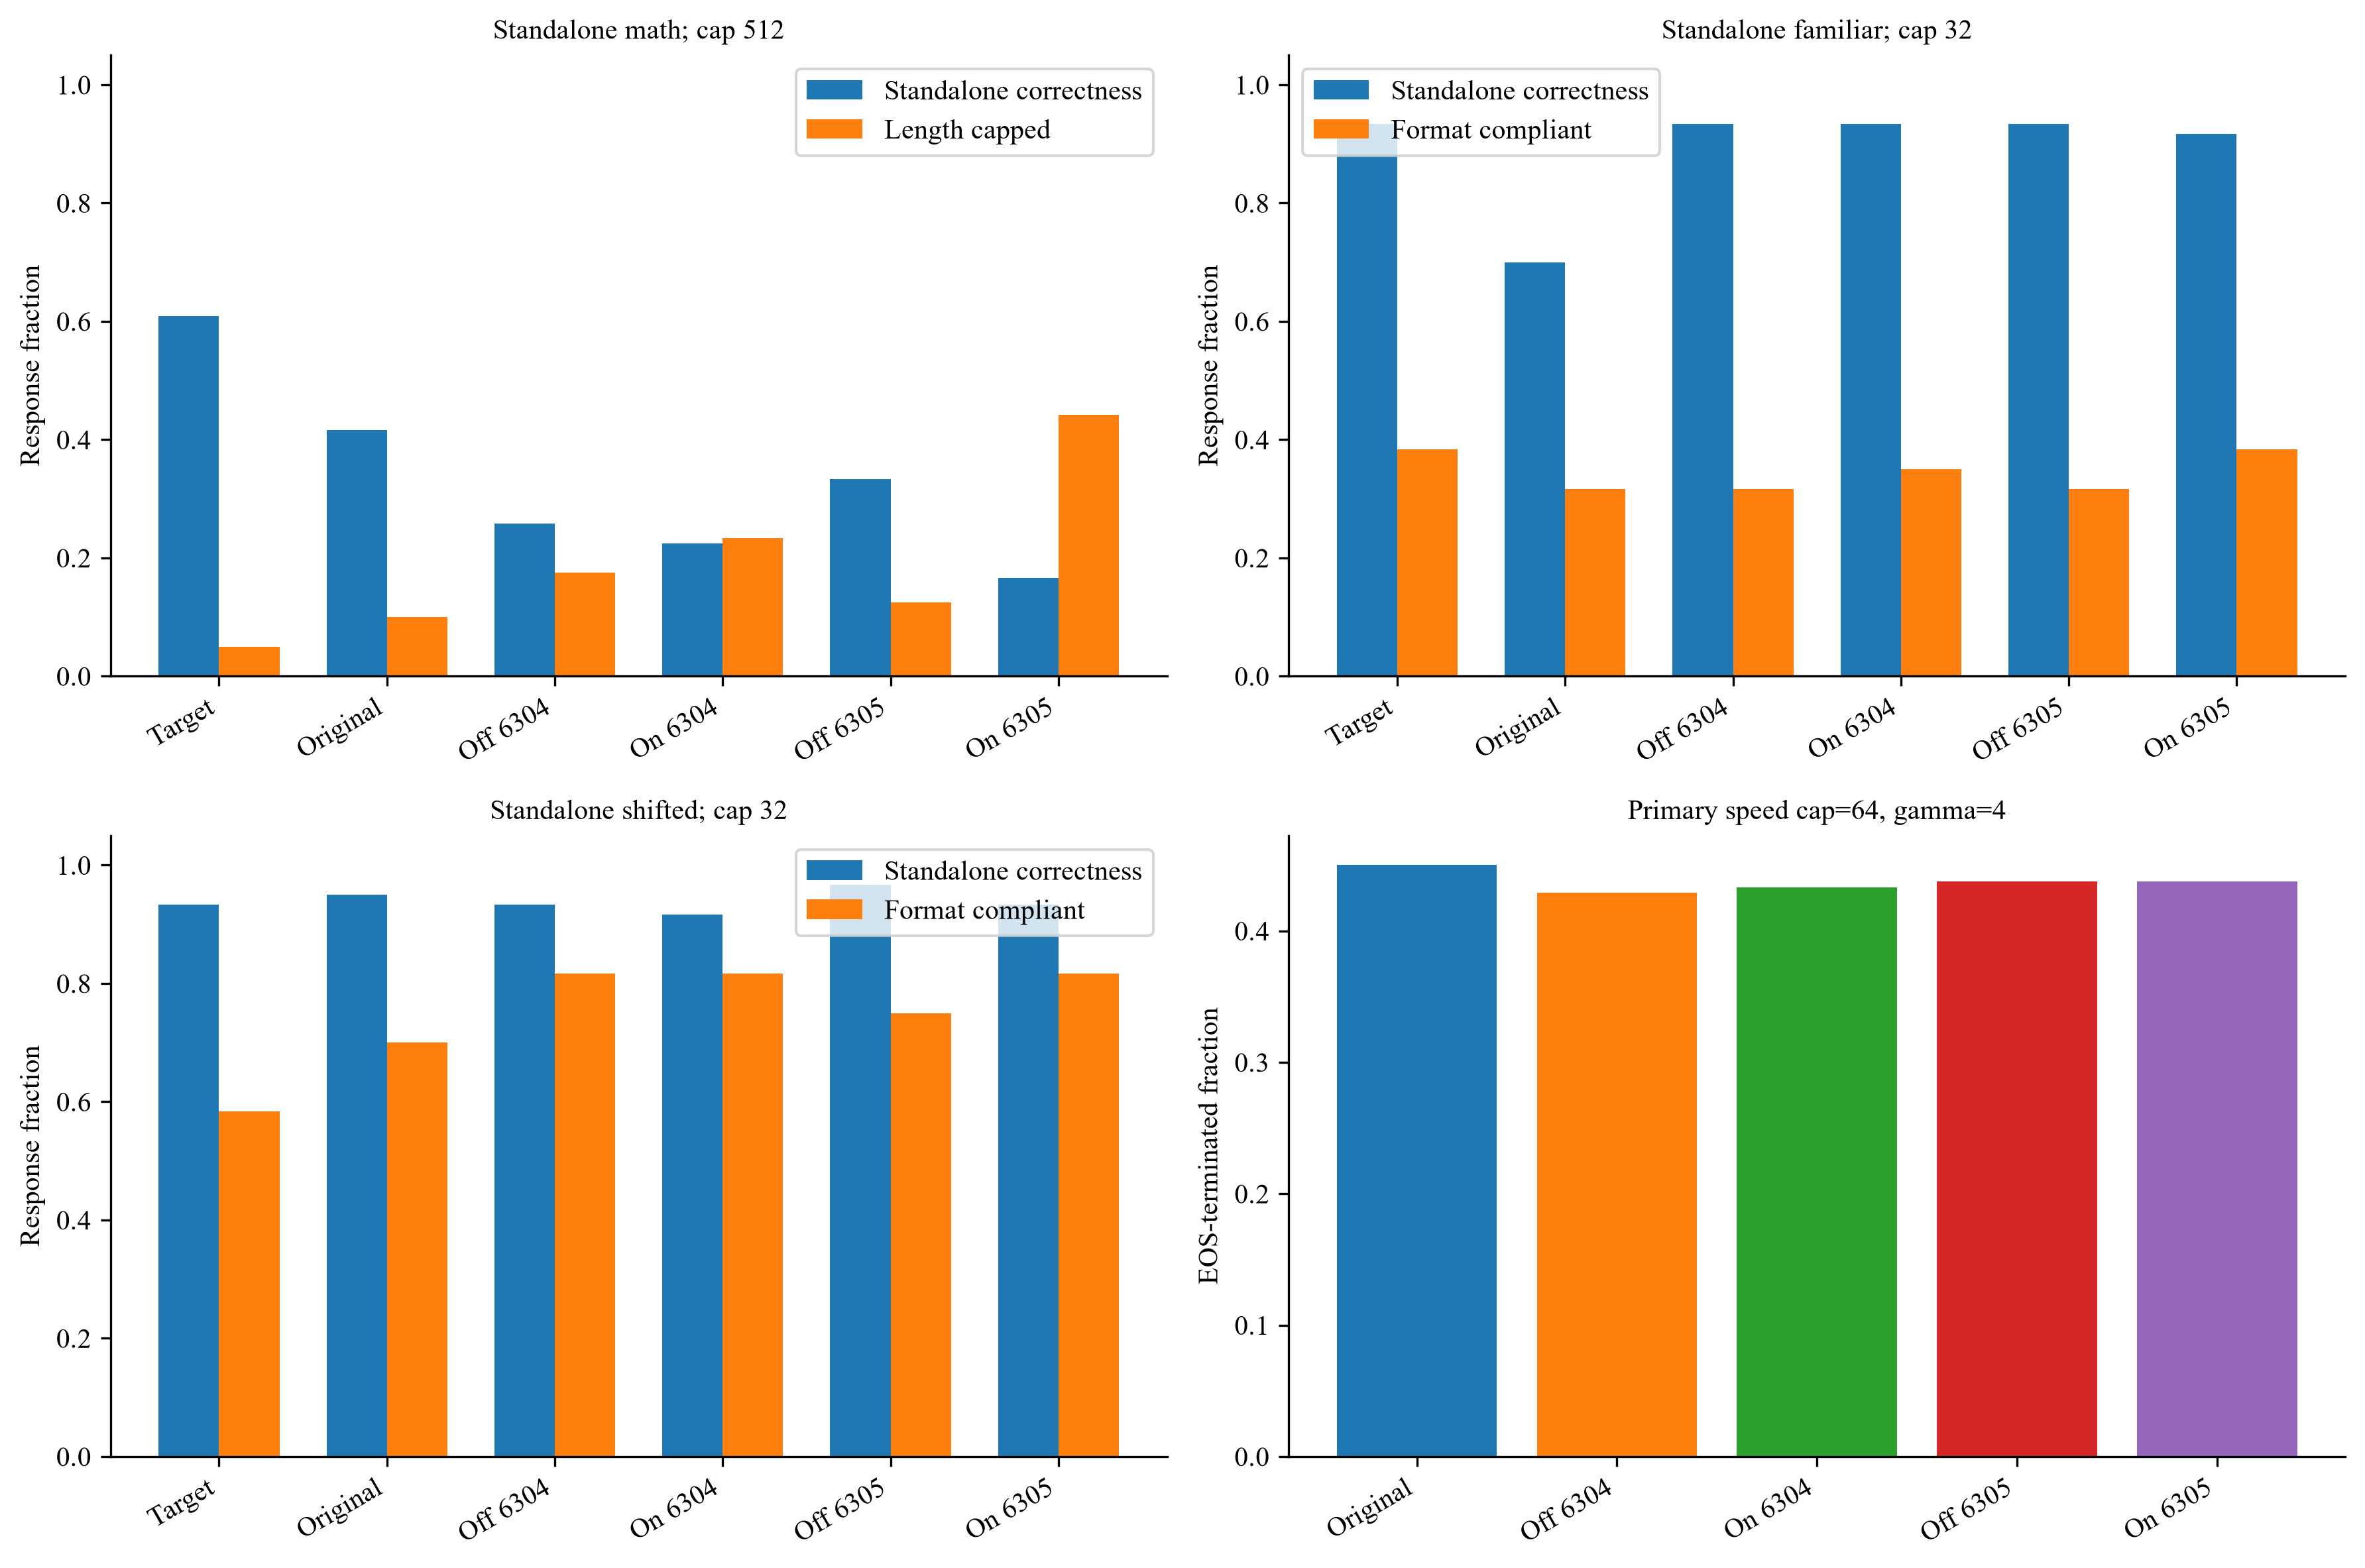

In [20]:
display_question(session, 'rq2', 'figures')


In [21]:
display_question(session, 'rq2', 'metrics')


## RQ-3: Probability overlap, verification work and projected versus measured speedup


In [22]:
display_question(session, 'rq3', 'tables')


tables/speculative_summary.csv
Showing 24/68 saved rows; full data are in the CSV.


,suite,draft,gamma,workload,paired_prompts,accepted_examined_fraction,accepted_proposed_fraction,mean_accepted_prefix,target_passes_per_output_token,draft_forward_passes,...,prefill_seconds,proposal_seconds,verification_seconds,sampling_seconds,maintenance_seconds,host_overhead_seconds,peak_allocated_bytes,end_to_end_tps_ratio,steady_decode_tps_ratio,request_latency_ratio
0,baseline,original,2,all,120,0.871389,0.823916,1.627823,0.541623,47.854167,...,0.069936,1.421243,0.681454,0.020107,0.004307,0.001248,4.119745e+09,0.610017,0.592482,0.590596
1,baseline,original,2,familiar,30,0.851681,0.796960,1.573903,0.683380,26.300000,...,0.069833,0.777594,0.379489,0.010876,0.003094,0.000719,4.118034e+09,0.533088,0.495797,0.534880
2,baseline,original,2,math,60,0.879604,0.827095,1.642905,0.399870,72.441667,...,0.069799,2.152857,1.024527,0.030521,0.005868,0.001849,4.121269e+09,0.691963,0.695298,0.691963
3,baseline,original,2,shifted,30,0.874667,0.844514,1.651580,0.683373,20.233333,...,0.070311,0.601663,0.297274,0.008510,0.002397,0.000574,4.118409e+09,0.542504,0.514109,0.475051
4,baseline,original,4,all,120,0.870559,0.746353,2.632719,0.445553,53.416667,...,0.069886,1.588663,0.468544,0.018099,0.004173,0.000888,4.124845e+09,0.611908,0.595942,0.611846
5,baseline,original,4,familiar,30,0.851430,0.717611,2.107898,0.648114,25.866667,...,0.069983,0.768451,0.241286,0.008173,0.002803,0.000487,4.122124e+09,0.498919,0.463797,0.599635
6,baseline,original,4,math,60,0.879720,0.739170,2.887416,0.279687,81.933333,...,0.069637,2.438512,0.705864,0.028136,0.005753,0.001310,4.128296e+09,0.704986,0.708757,0.704986
7,baseline,original,4,shifted,30,0.871365,0.789459,2.648147,0.574725,23.933333,...,0.070289,0.709178,0.221161,0.007951,0.002382,0.000447,4.120666e+09,0.565397,0.541370,0.470240
8,fixed64,off_policy_seed6304,2,all,24,0.886257,0.840618,1.668268,0.394857,71.437500,...,0.067747,2.056625,0.984008,0.028953,0.005326,0.001686,4.124540e+09,0.701478,0.705066,0.701478
9,fixed64,off_policy_seed6304,2,math,24,0.886257,0.840618,1.668268,0.394857,71.437500,...,0.067747,2.056625,0.984008,0.028953,0.005326,0.001686,4.124540e+09,0.701478,0.705066,0.701478


tables/paired_prompt_intervals.csv
Showing 24/340 saved rows; full data are in the CSV.


,suite,draft,gamma,workload,metric,estimate,ci_low,ci_high,paired_prompts,resamples,repetition_unit
0,baseline,original,2,all,end_to_end_tps_ratio,0.610017,0.590567,0.629342,120,2000,two repetitions averaged within prompt before ...
1,baseline,original,2,all,steady_decode_tps_ratio,0.592482,0.566230,0.617343,120,2000,two repetitions averaged within prompt before ...
2,baseline,original,2,all,request_latency_ratio,0.590596,0.545118,0.640939,120,2000,two repetitions averaged within prompt before ...
3,baseline,original,2,all,accepted_examined_fraction,0.871389,0.855446,0.887167,120,2000,two repetitions averaged within prompt before ...
4,baseline,original,2,all,accepted_proposed_fraction,0.823916,0.803463,0.844822,120,2000,two repetitions averaged within prompt before ...
5,baseline,original,2,familiar,end_to_end_tps_ratio,0.533088,0.497384,0.568561,30,2000,two repetitions averaged within prompt before ...
6,baseline,original,2,familiar,steady_decode_tps_ratio,0.495797,0.445645,0.546719,30,2000,two repetitions averaged within prompt before ...
7,baseline,original,2,familiar,request_latency_ratio,0.534880,0.422666,0.684212,30,2000,two repetitions averaged within prompt before ...
8,baseline,original,2,familiar,accepted_examined_fraction,0.851681,0.814662,0.887922,30,2000,two repetitions averaged within prompt before ...
9,baseline,original,2,familiar,accepted_proposed_fraction,0.796960,0.746142,0.847604,30,2000,two repetitions averaged within prompt before ...


tables/paired_draft_comparisons.csv


,draft,reference,gamma,metric,estimate,ci_low,ci_high,paired_prompts,resamples,repetition_unit
0,off_policy_seed6304,original,2,accepted_examined_fraction,0.015847,0.001962,0.030917,120,2000,two repetitions averaged within prompt before ...
1,off_policy_seed6304,original,2,end_to_end_tps_ratio,0.005568,-0.004044,0.015739,120,2000,two repetitions averaged within prompt before ...
2,on_policy_seed6304,original,2,accepted_examined_fraction,0.023054,0.006493,0.041569,120,2000,two repetitions averaged within prompt before ...
3,on_policy_seed6304,original,2,end_to_end_tps_ratio,0.006468,-0.003322,0.016757,120,2000,two repetitions averaged within prompt before ...
4,off_policy_seed6305,original,2,accepted_examined_fraction,0.019174,0.004924,0.034144,120,2000,two repetitions averaged within prompt before ...
5,off_policy_seed6305,original,2,end_to_end_tps_ratio,0.008995,0.000118,0.018021,120,2000,two repetitions averaged within prompt before ...
6,on_policy_seed6305,original,2,accepted_examined_fraction,0.016356,0.000337,0.034416,120,2000,two repetitions averaged within prompt before ...
7,on_policy_seed6305,original,2,end_to_end_tps_ratio,0.006222,-0.004142,0.017463,120,2000,two repetitions averaged within prompt before ...
8,on_policy_seed6304,off_policy_seed6304,2,accepted_examined_fraction,0.007207,-0.005260,0.020195,120,2000,two repetitions averaged within prompt before ...
9,on_policy_seed6304,off_policy_seed6304,2,end_to_end_tps_ratio,0.000900,-0.007831,0.009372,120,2000,two repetitions averaged within prompt before ...


tables/acceptance_prediction_correlations.csv
Showing 24/120 saved rows; full data are in the CSV.


,suite,draft,gamma,workload,metric,pearson_r,prompts,scope
0,primary,off_policy_seed6304,2,all,forward_kl,-0.478910,120,common teacher-bank expectations versus separa...
1,primary,off_policy_seed6304,2,all,tv,-0.577915,120,common teacher-bank expectations versus separa...
2,primary,off_policy_seed6304,2,all,expected_acceptance,0.577915,120,common teacher-bank expectations versus separa...
3,primary,off_policy_seed6304,2,familiar,forward_kl,0.047850,30,common teacher-bank expectations versus separa...
4,primary,off_policy_seed6304,2,familiar,tv,-0.282536,30,common teacher-bank expectations versus separa...
5,primary,off_policy_seed6304,2,familiar,expected_acceptance,0.282536,30,common teacher-bank expectations versus separa...
6,primary,off_policy_seed6304,2,math,forward_kl,-0.288764,60,common teacher-bank expectations versus separa...
7,primary,off_policy_seed6304,2,math,tv,-0.365975,60,common teacher-bank expectations versus separa...
8,primary,off_policy_seed6304,2,math,expected_acceptance,0.365975,60,common teacher-bank expectations versus separa...
9,primary,off_policy_seed6304,2,shifted,forward_kl,-0.699497,30,common teacher-bank expectations versus separa...


figures/acceptance_verification.png


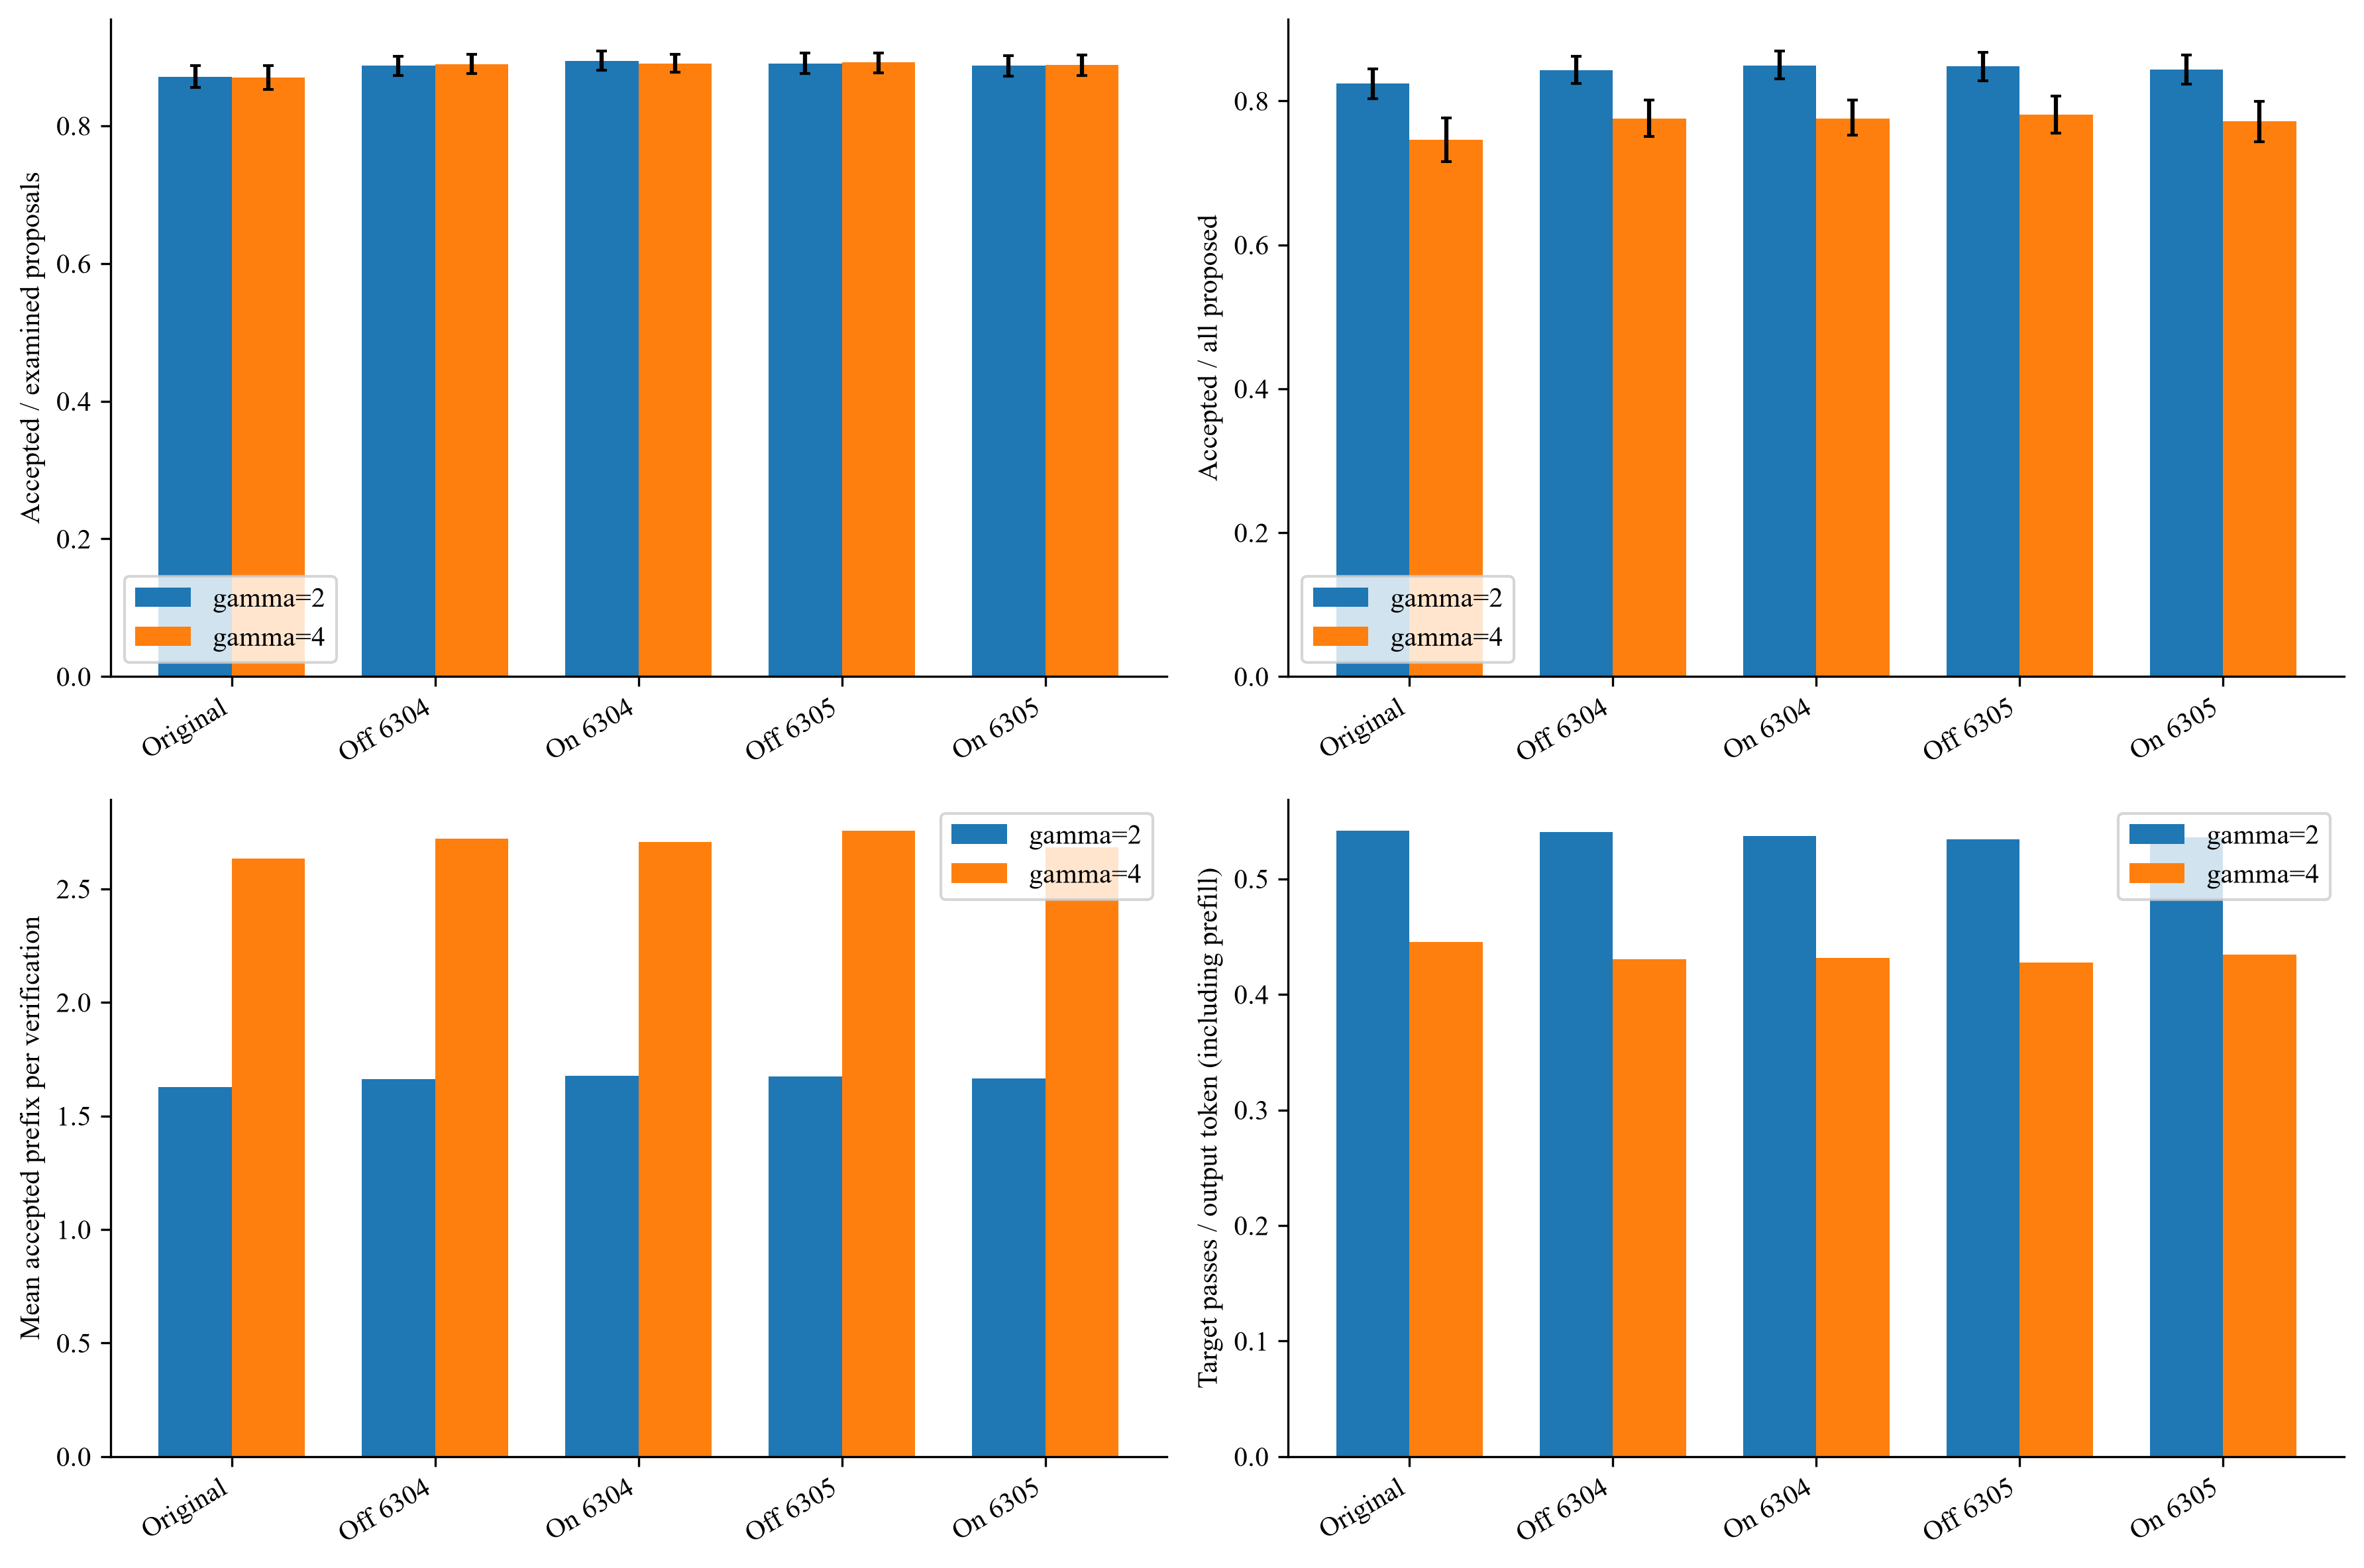

figures/predicted_measured_speedup.png


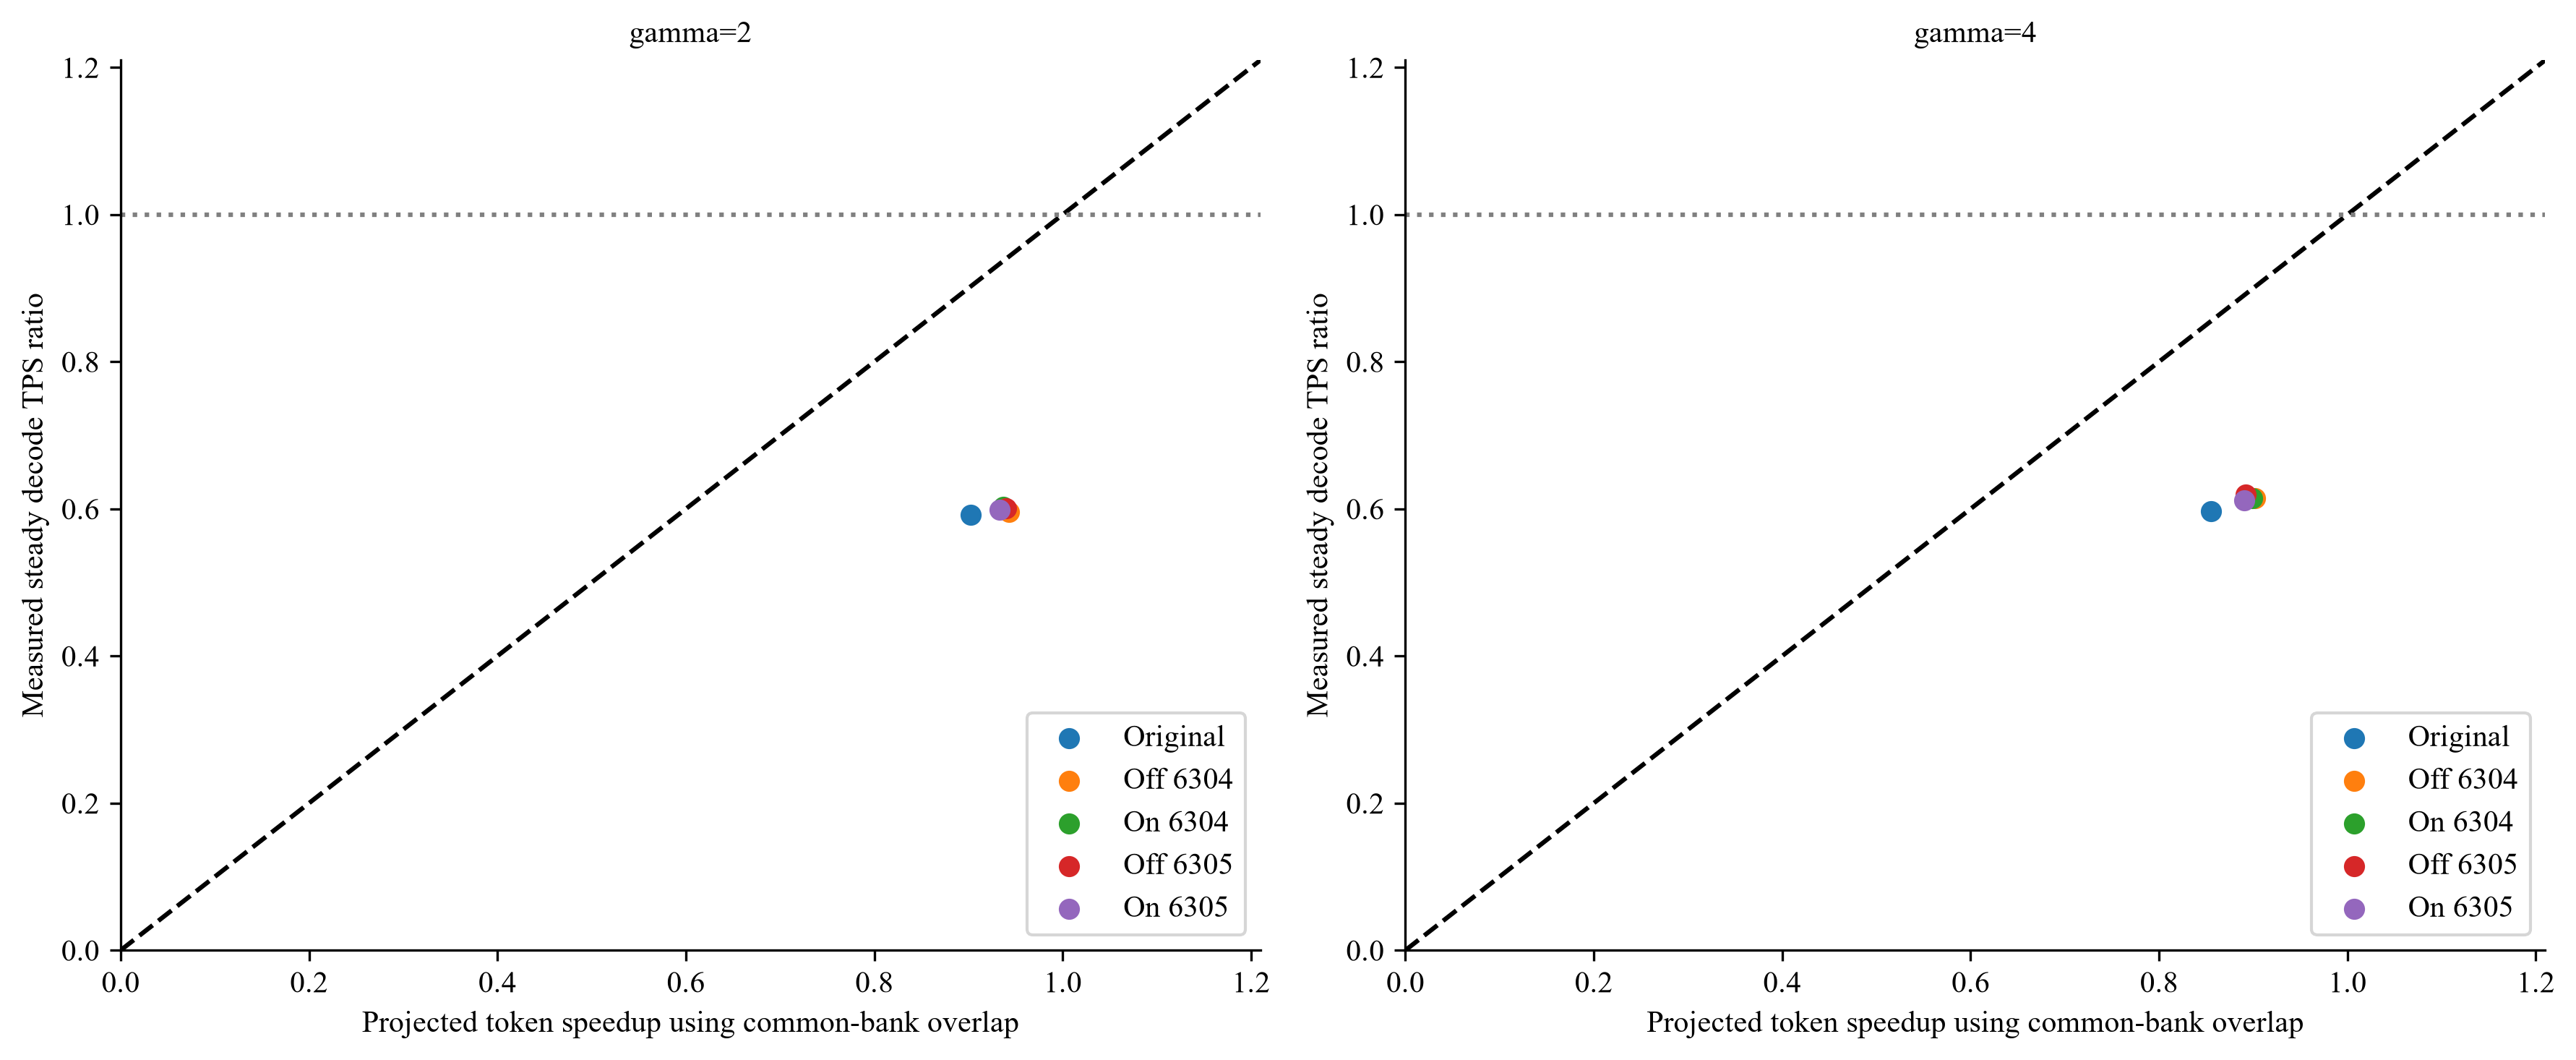

In [23]:
display_question(session, 'rq3', 'figures')


In [24]:
display_question(session, 'rq3', 'metrics')


## RQ-4: Draft/target costs, adapter overhead, EOS and training amortization


In [25]:
display_question(session, 'rq4', 'tables')


tables/isolated_decode_costs.csv


,draft,context_length,unmerged_wrapper,target_step_ms,draft_step_ms,c,v_gamma2,v_gamma4
0,off_policy_seed6304,256,False,33.668713,28.306660,0.840741,1.174876,1.180462
1,off_policy_seed6304,512,False,33.593863,28.584761,0.850892,1.192264,1.215069
2,off_policy_seed6304,64,False,33.508678,27.954789,0.834255,1.188969,1.187876
3,off_policy_seed6305,256,False,34.695482,28.928910,0.833795,1.173971,1.182609
4,off_policy_seed6305,512,False,33.728254,28.238817,0.837245,1.175788,1.171442
5,off_policy_seed6305,64,False,33.338089,27.908116,0.837124,1.186577,1.203708
6,on_policy_seed6304,256,False,33.723354,28.477559,0.844446,1.176613,1.196090
7,on_policy_seed6304,512,False,33.630303,28.834747,0.857404,1.191125,1.194257
8,on_policy_seed6304,64,False,33.066119,27.490498,0.831380,1.205691,1.192202
9,on_policy_seed6305,256,False,33.503579,28.291251,0.844425,1.204051,1.203396


tables/upfront_costs.csv


,draft,method,seed,teacher_pool_generation_seconds,student_rollout_seconds,teacher_scoring_seconds,student_backward_and_optimizer_seconds,merge_compute_seconds,merge_write_and_backup_seconds,observed_upfront_wall_seconds,measured_component_seconds,accounted_upfront_seconds,upfront_is_lower_bound,incomplete_wall_stages,cost_scope
0,off_policy_seed6304,off_policy,6304,3378.360252,0.000000,53.964058,194.477290,0.023576,12.235344,3703.181957,3639.060520,3703.181957,False,NaN,sum over pool/training/merge of max(recorded s...
1,on_policy_seed6304,on_policy,6304,0.000000,1838.321972,51.521290,186.035325,0.022315,13.112919,2122.461550,2089.013821,2122.461550,False,NaN,sum over pool/training/merge of max(recorded s...
2,off_policy_seed6305,off_policy,6305,3407.702978,0.000000,53.889299,195.318552,0.034822,12.872709,3746.601158,3669.818360,3746.601158,False,NaN,sum over pool/training/merge of max(recorded s...
3,on_policy_seed6305,on_policy,6305,0.000000,1828.672925,51.702530,186.686952,0.026704,12.478668,196.899156,2079.567780,2088.806645,True,train_on_policy_seed6305,sum over pool/training/merge of max(recorded s...


tables/deployment_break_even.csv


,suite,draft,gamma,workload,upfront_seconds,seconds_saved_per_request,upfront_is_lower_bound,break_even_requests,finite_break_even,comparison
0,primary,off_policy_seed6304,2,all,3703.181957,-0.715907,False,NaN,False,same-condition adjacent target-only request la...
1,primary,off_policy_seed6304,2,familiar,3703.181957,-0.460262,False,NaN,False,same-condition adjacent target-only request la...
2,primary,off_policy_seed6304,2,math,3703.181957,-0.968061,False,NaN,False,same-condition adjacent target-only request la...
3,primary,off_policy_seed6304,2,shifted,3703.181957,-0.467244,False,NaN,False,same-condition adjacent target-only request la...
4,primary,off_policy_seed6304,4,all,3703.181957,-0.777363,False,NaN,False,same-condition adjacent target-only request la...
5,primary,off_policy_seed6304,4,familiar,3703.181957,-0.673646,False,NaN,False,same-condition adjacent target-only request la...
6,primary,off_policy_seed6304,4,math,3703.181957,-0.970383,False,NaN,False,same-condition adjacent target-only request la...
7,primary,off_policy_seed6304,4,shifted,3703.181957,-0.495039,False,NaN,False,same-condition adjacent target-only request la...
8,primary,off_policy_seed6305,2,all,3746.601158,-0.699472,False,NaN,False,same-condition adjacent target-only request la...
9,primary,off_policy_seed6305,2,familiar,3746.601158,-0.417419,False,NaN,False,same-condition adjacent target-only request la...


figures/execution_costs.png


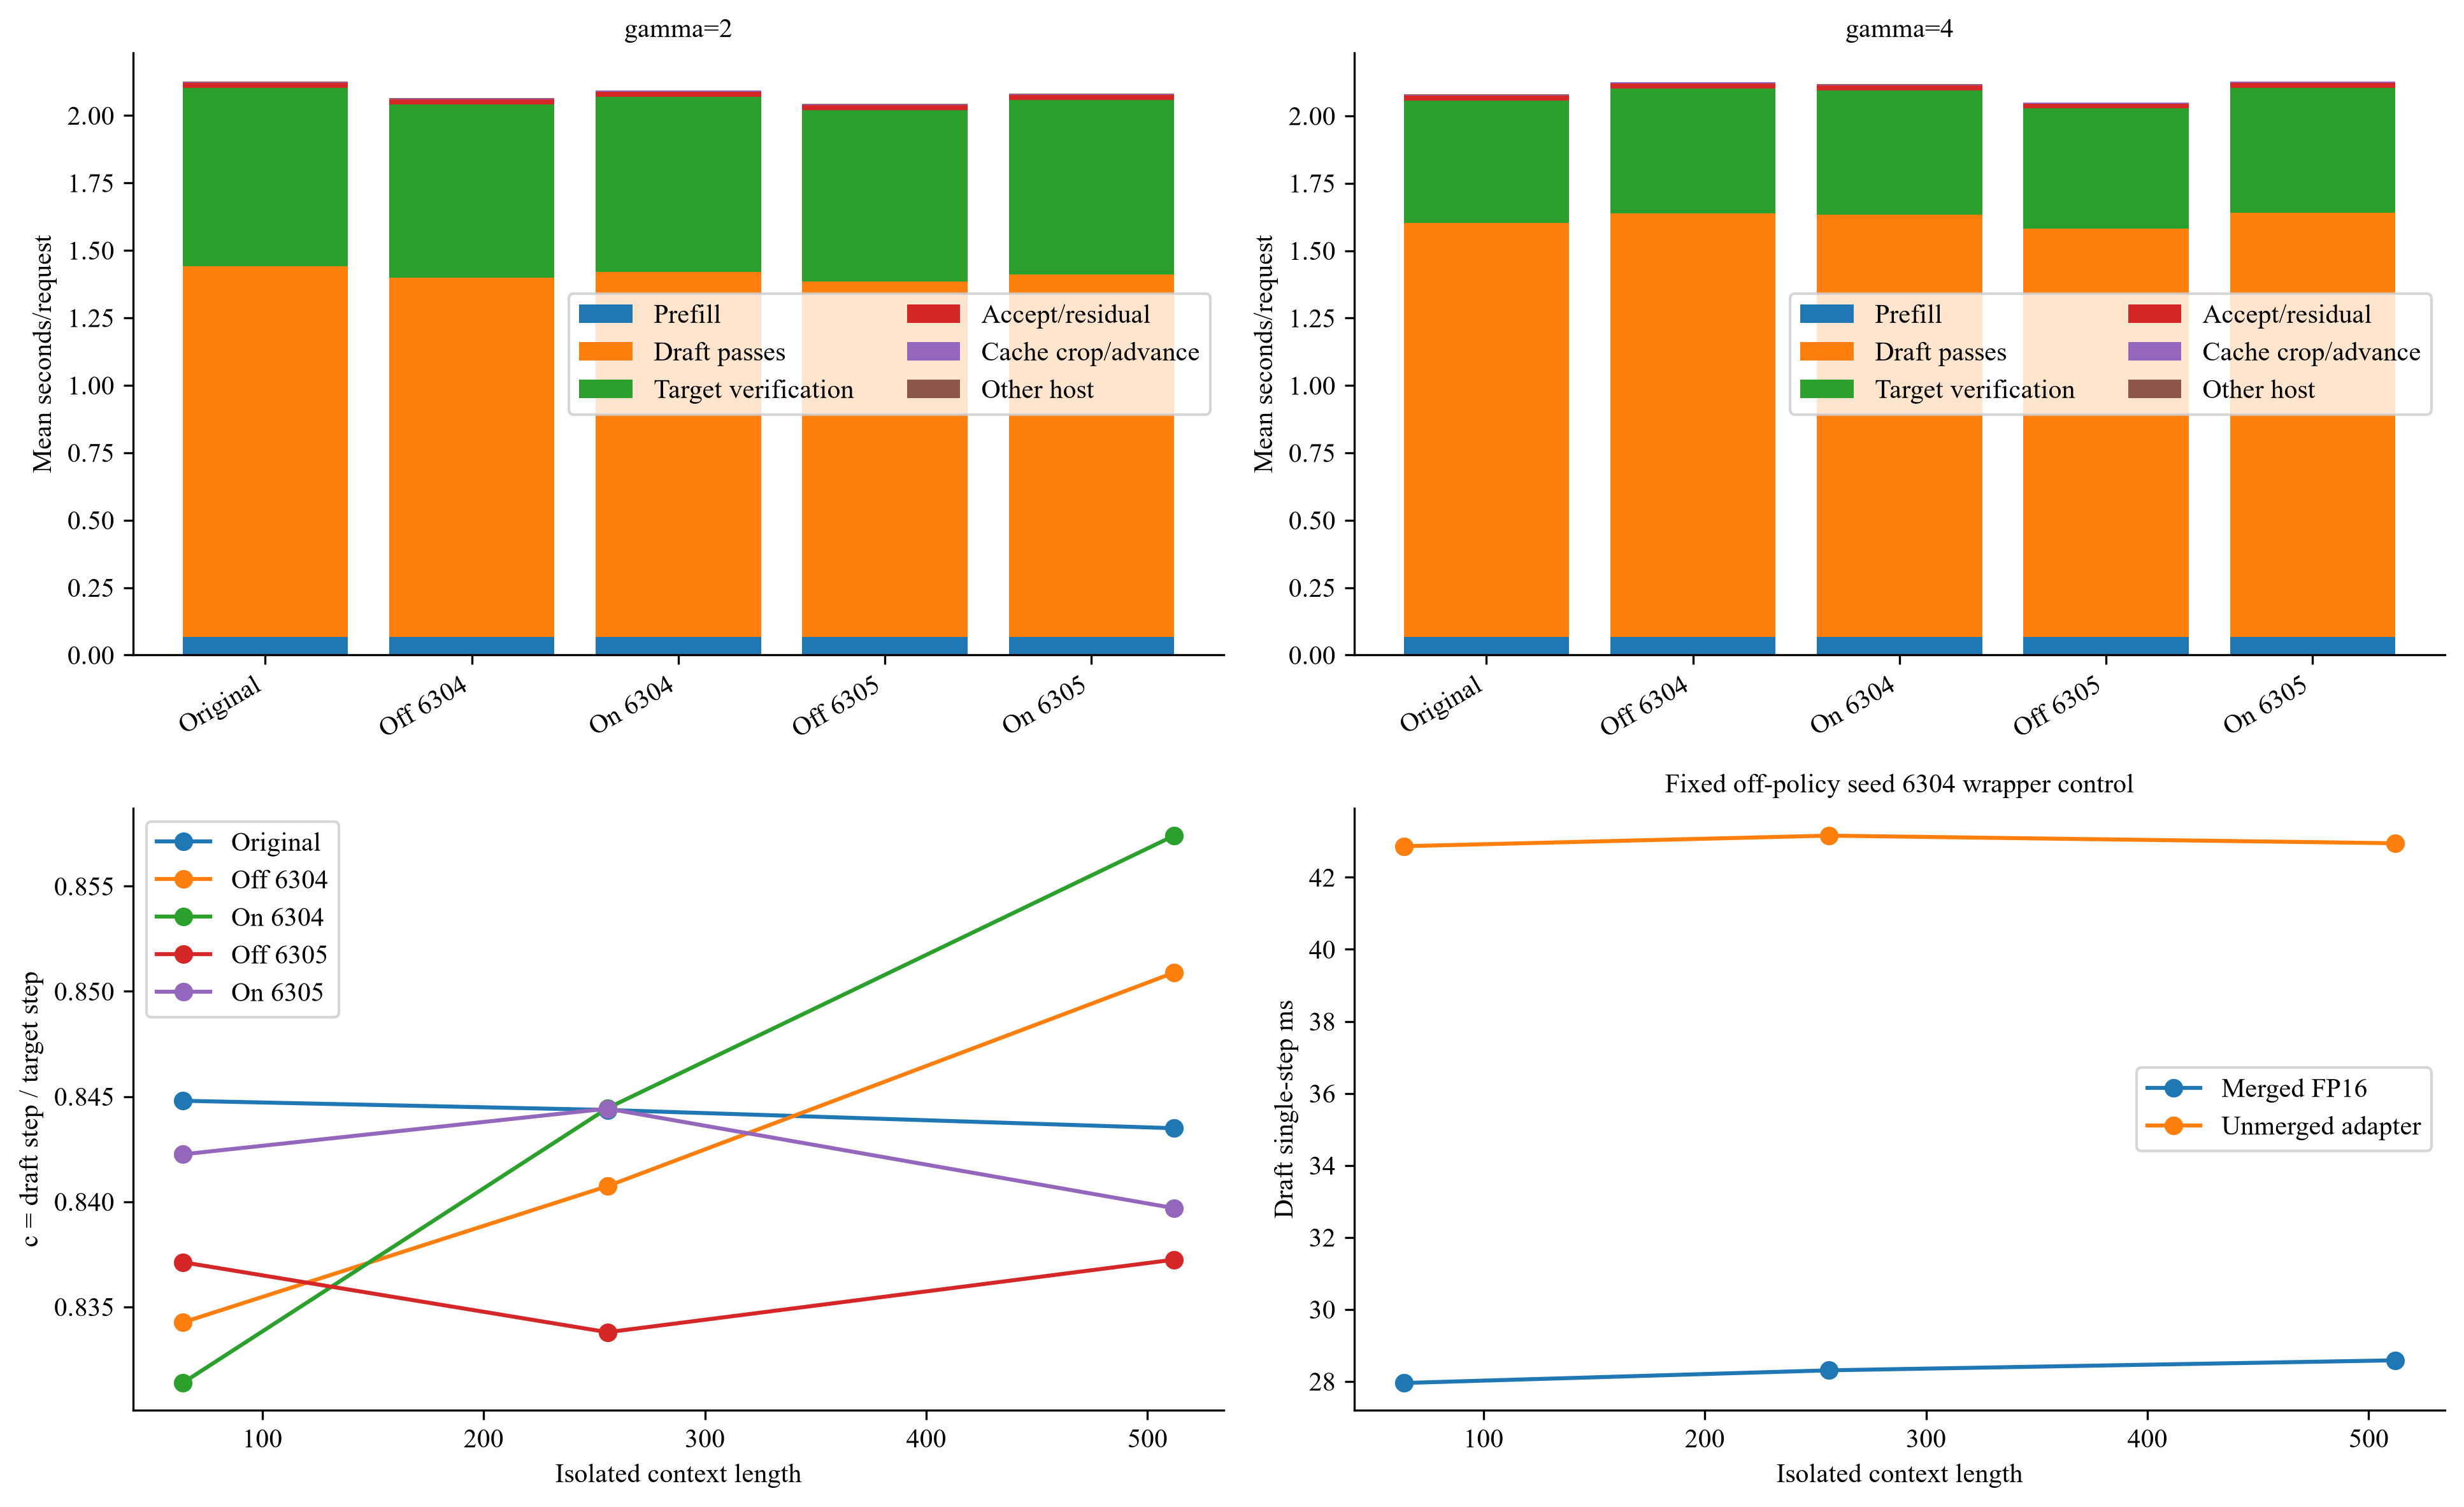

figures/training_amortization.png


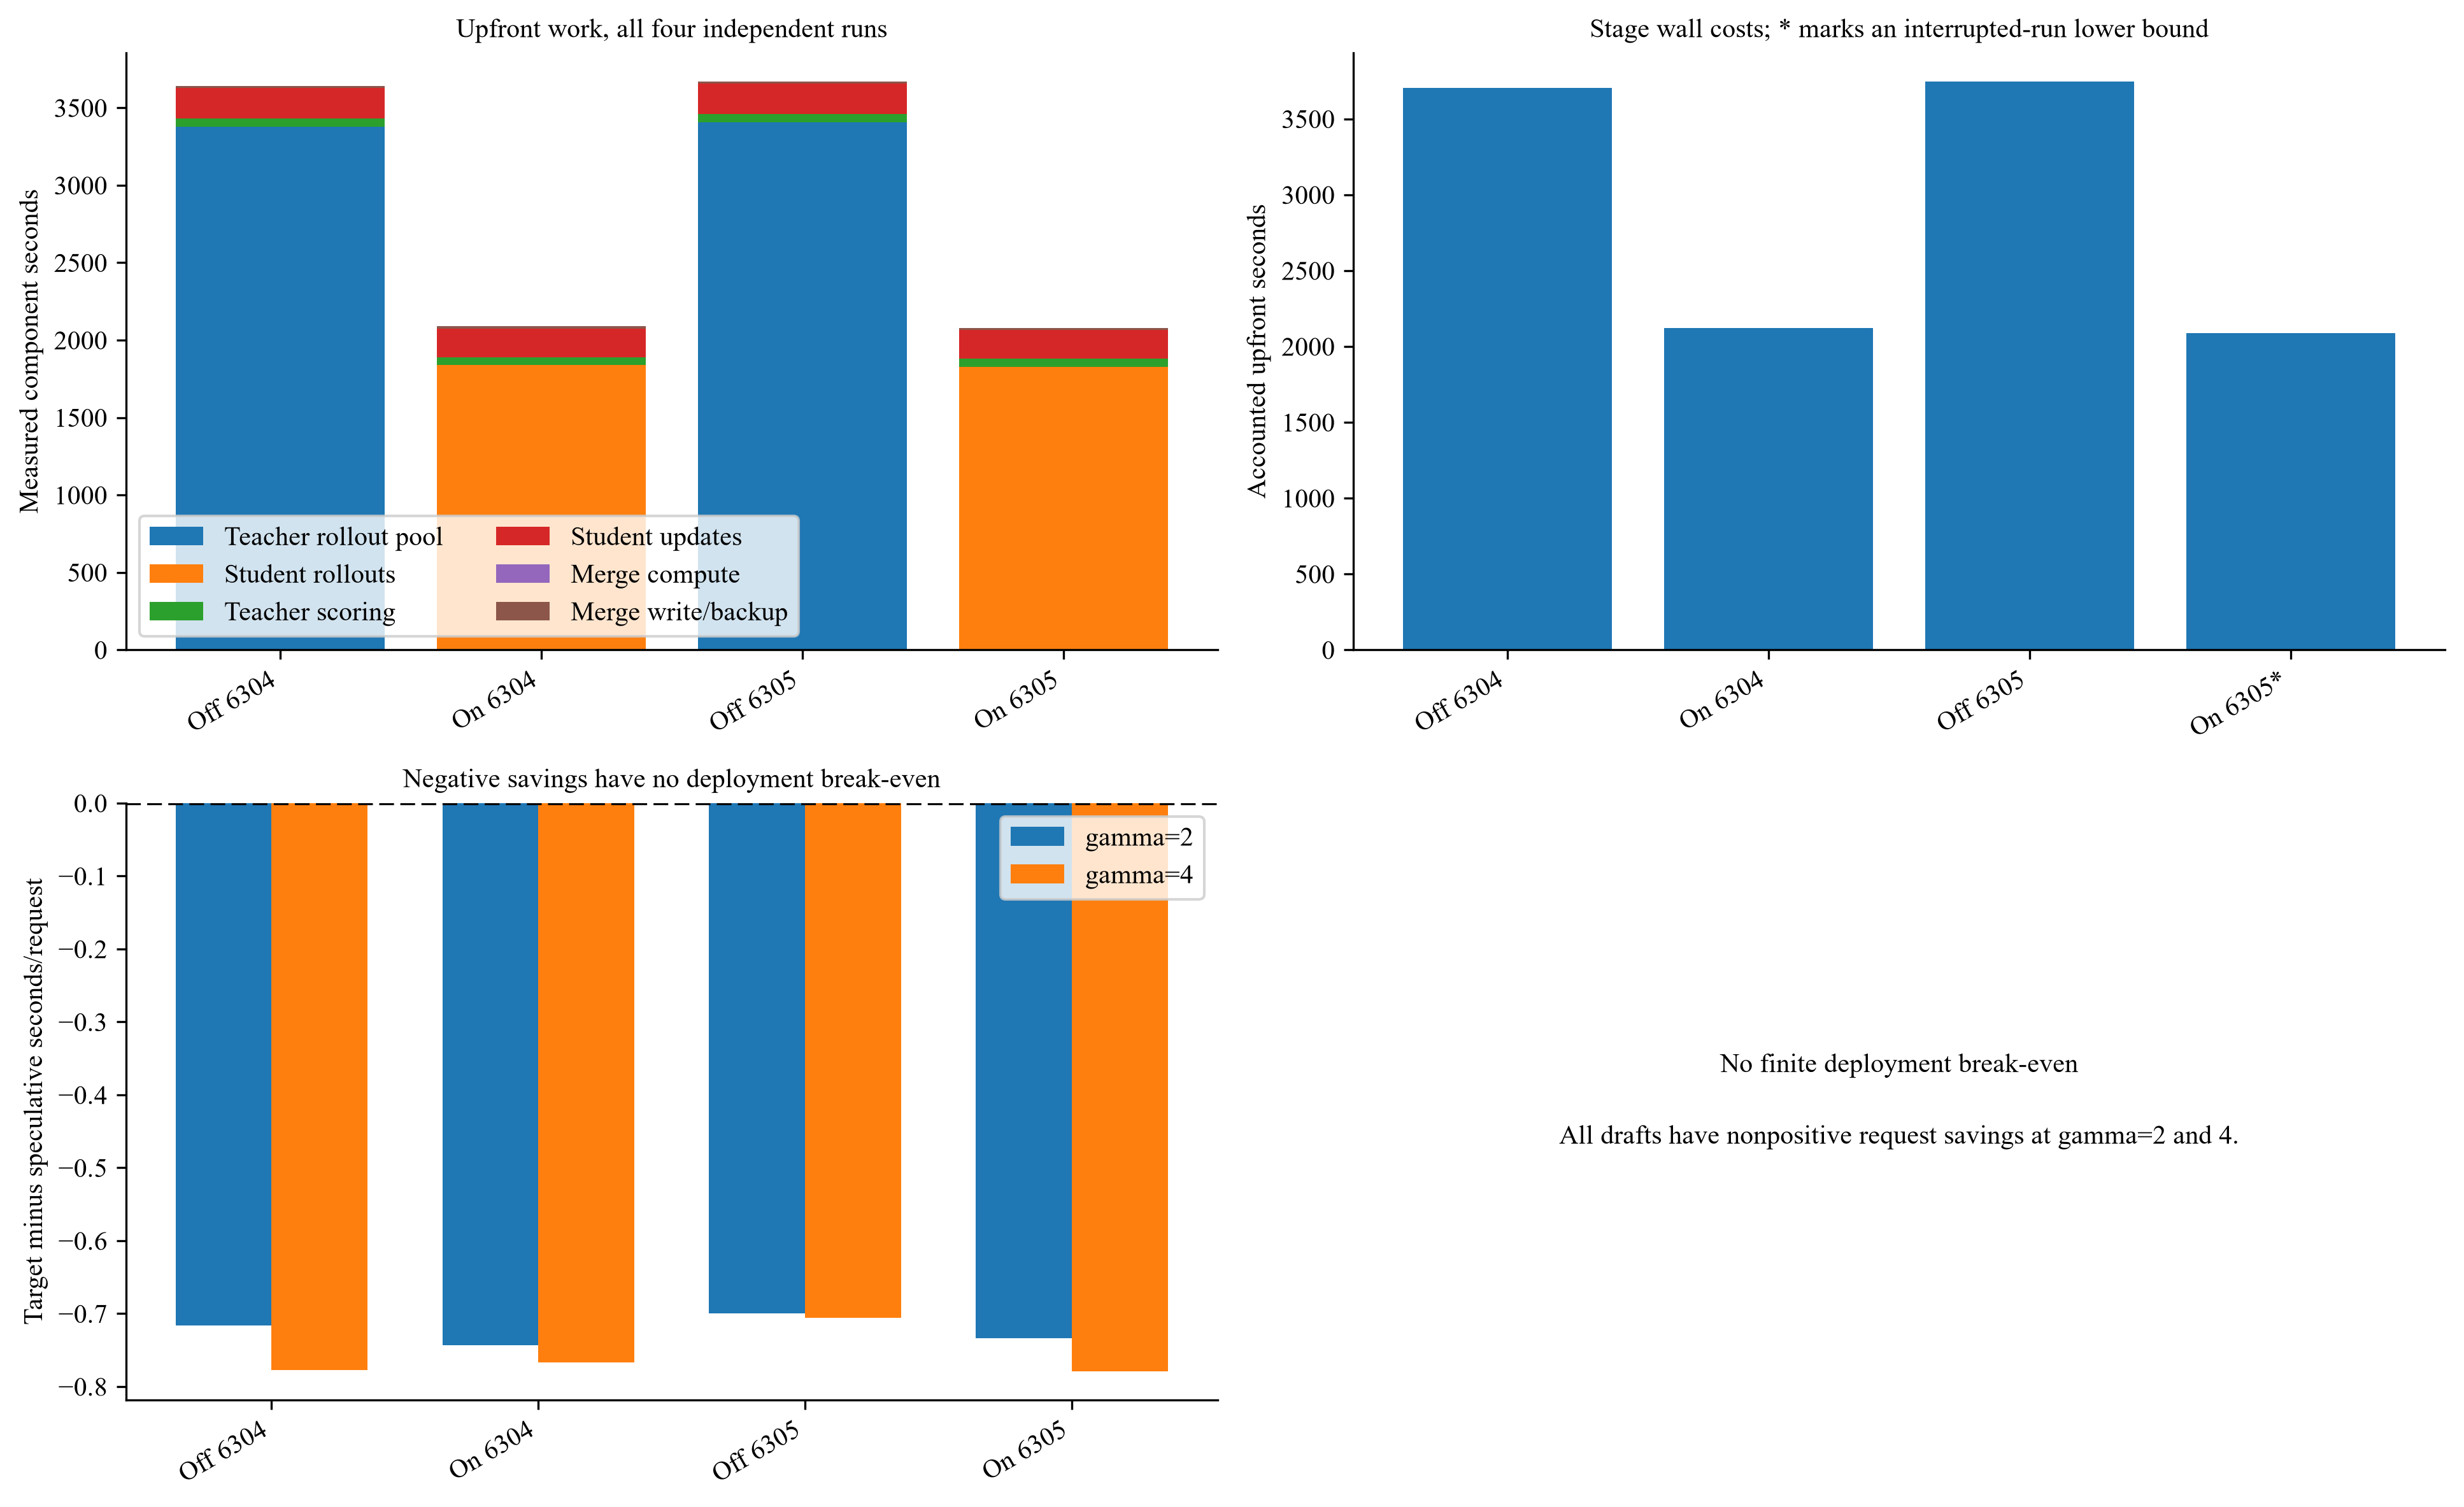

In [26]:
display_question(session, 'rq4', 'figures')


In [27]:
display_question(session, 'rq4', 'metrics')


### Fixed matched-prompt continuations

Use fixed prompt indices [0,30,60,90], repetition 0, with every draft and both proposal lengths. These are short speed-test continuations and must not be scored as completed mathematical answers.


In [28]:
from Task_3.common.artifacts import read_json
examples = read_json(session.paths['results'] / 'examples/matched_continuations.json')
display(pd.DataFrame([{key: row[key] for key in ['prompt_id', 'draft', 'gamma', 'workload', 'target_text', 'speculative_text']} for row in examples]))
prefixes = read_json(session.paths['results'] / 'examples/aligned_prefixes.json')
display(pd.DataFrame([{key: row.get(key) for key in ['prefix_id', 'draft', 'position', 'forward_kl', 'tv', 'target_next_token', 'student_next_token', 'target_next_token_text', 'student_next_token_text']} for row in prefixes]).head(30))
print('Full fixed matched-prefix contexts and disagreements: examples/aligned_prefixes.json')


,prompt_id,draft,gamma,workload,target_text,speculative_text
0,GSM8K-test-0000,off_policy_seed6304,2,math,To determine how much Janet makes every day at...,To determine how much Janet makes every day at...
1,GSM8K-test-0030,off_policy_seed6304,2,math,"To determine how much money Milly will lose, w...","To determine how much money Milly will lose, w..."
2,SHORT-familiar-0000,off_policy_seed6304,2,familiar,May,May
3,SHORT-shifted-0000,off_policy_seed6304,2,shifted,October,October
4,GSM8K-test-0000,off_policy_seed6304,4,math,To determine how much Janet makes every day at...,To determine how much Janet makes every day at...
...,...,...,...,...,...,...
35,SHORT-shifted-0000,original,2,shifted,October,October
36,GSM8K-test-0000,original,4,math,To determine how much Janet makes every day at...,To determine how much Janet makes every day at...
37,GSM8K-test-0030,original,4,math,"To determine how much money Milly will lose, w...",Let's break down the problem step by step to c...
38,SHORT-familiar-0000,original,4,familiar,May,May


,prefix_id,draft,position,forward_kl,tv,target_next_token,student_next_token,target_next_token_text,student_next_token_text
0,teacher:GSM8K-test-0000:p001,off_policy_seed6304,1,0.069569,0.088463,1249,1249,To,To
1,teacher:GSM8K-test-0000:p009,off_policy_seed6304,9,0.009937,0.010470,518,518,at,at
2,teacher:GSM8K-test-0000:p010,off_policy_seed6304,10,0.000115,0.000229,279,279,the,the
3,teacher:GSM8K-test-0000:p001,off_policy_seed6305,1,0.040924,0.073505,1249,1249,To,To
4,teacher:GSM8K-test-0000:p009,off_policy_seed6305,9,0.013003,0.012667,518,518,at,at
5,teacher:GSM8K-test-0000:p010,off_policy_seed6305,10,0.000174,0.000487,279,279,the,the
6,teacher:GSM8K-test-0000:p001,on_policy_seed6304,1,0.051231,0.041462,1249,1249,To,To
7,teacher:GSM8K-test-0000:p009,on_policy_seed6304,9,0.025572,0.032276,518,518,at,at
8,teacher:GSM8K-test-0000:p010,on_policy_seed6304,10,0.000298,0.000857,279,279,the,the
9,teacher:GSM8K-test-0000:p001,on_policy_seed6305,1,0.030813,0.038658,1249,1249,To,To


Full fixed matched-prefix contexts and disagreements: examples/aligned_prefixes.json


## Completion and download

Download `MyDrive/ATML_PA4/PA_4/Task_3/results/` into local `Task_3/results/`, preserving the run directory. Large recovery and merged checkpoints may stay on Drive for replay. Local ATML Run All displays the verified Colab evidence. Delete the downloaded ZIP only after audit and replay pass.


In [29]:
display(session.finish())


Validating 13029 Task 3 evidence files...


Verified four 40,000-token runs, training annotations and adapter merges.


Verified seven frozen prefix banks and all five drafts on identical prefix IDs.


Verified baseline: 480 adjacent-control pairs.


Verified primary: 2400 adjacent-control pairs.


Verified fixed64: 480 adjacent-control pairs.


{'status': 'complete',
 'computed_on': 'Google Colab',
 'run_id': 'task3_seed6304_v1'}